- DSC550-T303 Data Mining (2265-1)
- Final Term Project Submission: Predicting 30 Day Diabetic Hospital Readmission Risk
- Shelia Howard

## DSC550 Final Term Project

### Introduction

This final project notebook combines and updates the full DSC550 healthcare data mining project focused on predicting whether diabetic hospital encounters are associated with readmission within 30 days. The notebook includes the original project problem and exploratory data analysis from Milestone 1, the data preparation and feature engineering work from Milestone 2, the model building and evaluation work from Milestone 3, and a final project section that clearly documents what was added after Milestone 3.

Throughout the notebook, each code block includes comments explaining what the code is doing and why the step matters.

The project is organized around a healthcare decision-support question: can a hospital system use available encounter, utilization, medication, diagnosis, and demographic information to identify patients who may be at higher risk of 30 day readmission while also remaining alert to potential differences across demographic groups?

The final submission includes the following major sections:

1. Introduction and business problem framing.
2. Data source explanation.
3. Organized summary of Milestones 1 through 3.
4. Exploratory data analysis with project visuals.
5. Data preparation and feature engineering.
6. Model building and evaluation.
7. Final updates added since Milestone 3.
8. Final project writeup, conclusion, deployment readiness review, recommendations, challenges, and future opportunities.

The final project writeup is included as a dedicated section within this notebook so the exported PDF contains both the technical code workflow and the written project summary required for final submission.

## Milestone 2 Context Carried Forward

This notebook builds on Milestone 1 and continues the healthcare data mining project focused on predicting 30 day hospital readmission risk for diabetic patients while remaining aware of potential healthcare bias. Milestone 1 introduced the project, loaded the Diabetes 130-US Hospitals dataset, created a binary readmission target, and performed exploratory visual analysis across readmission outcome, race, gender, time in hospital, and age.

Milestone 2 moves from exploration into data preparation. The goal of this section is to prepare the dataset for the future model building and evaluation phase. The notebook documents feature selection, data extraction, missing data treatment, feature transformation, feature engineering, dummy variable creation, and class imbalance planning. Throughout the notebook, each code block includes comments explaining what the code is doing and why the step matters.

A key concern carried forward from Milestone 1 is that the target feature is imbalanced. Because fewer encounters are readmitted within 30 days than not readmitted within 30 days, the prepared modeling dataset must support later evaluation with metrics beyond accuracy, such as recall, precision, F1-score, ROC-AUC, and PR-AUC. At the Milestone 2 stage, the notebook did not train the final model yet; instead, it prepared the data in a way that supports responsible modeling in Milestone 3.

## Milestone 1 Summary and Prior Work

The cells below preserve the prior Milestone 1 project context, initial inspection, target creation, and exploratory graphs. This is included because the assignment instructions ask that Milestones 1 and 2 build on each other and remain clear in the same project workflow.


## Exploring Potential Bias in Predicting 30 Day Hospital Readmissions for Diabetic Patients

### Introduction

This notebook presents an original healthcare-focused data mining project idea for DSC550. The business problem explored here is whether a hospital system could build a model to predict which diabetic patients are more likely to be readmitted within 30 days, while also checking whether important demographic groups appear to experience different patterns in the data. This topic matters because readmissions are costly for health systems, can reflect gaps in care coordination, and raise fairness concerns when outcomes differ across race, gender, or age groups.

The target for the proposed model is **30 day readmission status**, using the `readmitted` field from the dataset. For Milestone 1, the goal is not to build the final model yet, but to define the problem, examine the data visually, and identify early patterns that may influence later modeling decisions. The project uses the **Diabetes 130 US Hospitals for Years 1999 to 2008** dataset from the UCI Machine Learning Repository, which contains over 100,000 hospital encounters and includes clinical and demographic variables.

The broader question behind this project is: **Can a healthcare organization predict readmission risk in a way that improves follow up care while remaining alert to possible bias across patient groups?** This question gives the project a business purpose and a responsible analytical lens.


### Project Narrative

Hospitals have a strong business and clinical reason to reduce preventable readmissions, especially for patients with chronic conditions such as diabetes. A 30 day readmission can signal gaps in discharge planning, medication management, access to follow up care, or broader inequities that affect patient outcomes. For this project, the proposed business problem is to help a healthcare organization identify diabetic patients who may be at higher risk of returning to the hospital within 30 days of discharge. A useful model could support earlier interventions such as care coordination outreach, medication review, discharge education, or social support referrals.

The target for the model is whether a patient was **readmitted within 30 days**, derived from the dataset's `readmitted` variable. While prediction is the operational goal, this project adds a second layer that gives it a more original and responsible focus: examining whether patterns in readmission differ across demographic groups such as race, gender, and age. In healthcare, a model can appear accurate overall while still reflecting or reinforcing unequal outcomes for different populations. Because of that risk, this project treats bias awareness as part of the business problem rather than as an afterthought.

The dataset comes from the UCI Machine Learning Repository and includes more than 100,000 diabetic hospital encounters across 130 US hospitals. It contains patient demographics, utilization history, medication information, and hospital stay details that make it appropriate for both exploratory analysis and later model development. 

In this milestone, the notebook focuses on graphical analysis to understand the structure of the problem, inspect the target distribution, and look for early signs of variation that may matter for fairness, model selection, and feature preparation in later milestones. Because the outcome variable is binary, this project will be framed as a classification problem. Initial modeling will likely begin with logistic regression as a baseline approach, with the potential to evaluate more advanced models such as decision trees or ensemble methods in later milestones. Because the target is whether a patient was readmitted within 30 days, this project will be treated as a binary classification problem.


### Environment Setup

The following code imports the libraries needed for data loading, data inspection, and visualization. This step is important because the notebook depends on pandas for tabular analysis, matplotlib and seaborn for charts, and the UCI loader for direct access to the source dataset.


In [1]:
# If running this notebook in a new environment, install the UCI repository package first:
# pip install ucimlrepo

# Import the pandas library so the notebook can work with tabular data in DataFrame form.
import pandas as pd

# Import the numpy library so the notebook can use numeric operations and array-based tools when needed.
import numpy as np

# Import matplotlib.pyplot so the notebook can create charts for the required graphical analysis.
import matplotlib.pyplot as plt

# Import seaborn so the notebook can make cleaner statistical graphics with less code.
import seaborn as sns

# Import fetch_ucirepo so the notebook can load the dataset directly from the UCI Machine Learning Repository.
from ucimlrepo import fetch_ucirepo



# Set a seaborn theme so all graphs use a consistent academic style that is easier to read.
sns.set_theme(style="whitegrid")

# Set a larger default figure size so chart labels and titles are easier to see in the notebook and PDF export.
plt.rcParams["figure.figsize"] = (10, 6)


### Load the Dataset

This code downloads the dataset, separates the predictors and target provided by the UCI loader, and then combines them into one working DataFrame. That matters because exploratory analysis is easier when all fields needed for charts and summaries are stored in one place.


In [2]:
# Import the warnings library so the notebook can suppress a known dataset loading warning.
import warnings

# Import DtypeWarning so only the mixed-type dataset warning is suppressed.
from pandas.errors import DtypeWarning

# Import Path so the notebook can check whether a local fallback CSV file exists.
from pathlib import Path

# Store the expected local fallback file name for environments where UCI cannot be reached.
local_data_path = Path("diabetic_data.csv")

# Start a try block so the notebook can attempt the original live UCI dataset load first.
try:
    # Temporarily suppress the mixed-type warning produced inside fetch_ucirepo().
    with warnings.catch_warnings():
        # Ignore DtypeWarning because payer_code is later handled as a categorical feature.
        warnings.simplefilter("ignore", DtypeWarning)

        # Fetch the diabetes readmission dataset from the UCI repository.
        diabetic_data = fetch_ucirepo(id=296)

    # Store feature variables from the UCI loader.
    X = diabetic_data.data.features.copy()

    # Store target variable from the UCI loader.
    y = diabetic_data.data.targets.copy()

    # Combine the feature and target data into one DataFrame.
    df = pd.concat([X, y], axis=1)

    # Document which loading method worked.
    print("Dataset loaded directly from UCI using fetch_ucirepo().")

# Catch any exception caused by SSL certificates, server access, or internet restrictions.
except Exception as error:
    # Print the original error so the notebook documents why the fallback path is being used.
    print("UCI loading failed. Original error:", error)

    # Check whether the local fallback CSV file exists in the same folder as the notebook.
    if local_data_path.exists():
        # Load the local CSV file when the live UCI connection is unavailable.
        df = pd.read_csv(local_data_path, low_memory=False)

        # Document that the local dataset was loaded successfully.
        print("Dataset loaded from local diabetic_data.csv fallback file.")

    # Stop with a clear message if neither the UCI connection nor the local file is available.
    else:
        # Raise a helpful file-not-found error that explains the next action.
        raise FileNotFoundError("The dataset could not be loaded from UCI and diabetic_data.csv was not found in the notebook folder.")

# Replace question-mark placeholders with proper missing values before inspection.
df = df.replace("?", np.nan)

# Convert payer_code to a string column because it contains mixed values.
if "payer_code" in df.columns:
    df["payer_code"] = df["payer_code"].astype("string")

# Display dataset shape.
print("Dataset shape:", df.shape)

# Preview the first few rows.
df.head()


Dataset loaded directly from UCI using fetch_ucirepo().
Dataset shape: (101766, 48)


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,Caucasian,Female,[0-10),NaN,6,25,1,1,<NA>,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,No,No,NO
1,Caucasian,Female,[10-20),NaN,1,1,7,3,<NA>,NaN,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,<NA>,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
3,Caucasian,Male,[30-40),NaN,1,1,7,2,<NA>,NaN,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,Caucasian,Male,[40-50),NaN,1,1,7,1,<NA>,NaN,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


The dataset loading block includes a local CSV fallback so the notebook can still run if the UCI repository is unavailable because of an internet, server, or SSL certificate issue. The `payer_code` column is converted to a string type because it may contain mixed values. This step supports reproducibility and prevents the project from depending entirely on a live web connection.

## Initial Inspection

This code reviews the dataset structure, available columns, data types, and numeric summaries. It is important because early inspection helps identify the target, spot missing data, and decide which variables are useful for the first round of visual analysis.


In [3]:
# Display the column names so the notebook can verify which variables are available for the project.
print(df.columns.tolist())

# Display general DataFrame information so the notebook can inspect data types and missing-value patterns.
df.info()

# Display descriptive statistics for numeric columns so the notebook can understand basic numeric ranges and distributions.
display(df.describe().T)

# Display the number of missing values in each column so the notebook can identify fields that may need cleaning later.
missing_summary = df.isna().sum().sort_values(ascending=False)

# Show only columns with missing values to keep the output focused.
display(missing_summary[missing_summary > 0])

['race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 48 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0 

,count,mean,std,min,25%,50%,75%,max
admission_type_id,101766.0,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0


weight               98569
max_glu_serum        96420
A1Cresult            84748
medical_specialty    49949
payer_code           40256
race                  2273
diag_3                1423
diag_2                 358
diag_1                  21
dtype: int64

The initial inspection shows that several fields contain missing values, particularly `weight`, `payer_code`, `medical_specialty`, `max_glu_serum`, and `A1Cresult`. These missing values are not addressed at this stage because the focus of this milestone is exploratory analysis rather than final data preparation. However, these patterns will need to be handled carefully in later stages to ensure accurate and reliable model performance.

## Prepare a Target for the Project

This code converts the original readmission field into a simpler binary target for the project. That step is important because the milestone asks for a clear model target, and later classification work is more straightforward when the outcome is coded consistently as a binary indicator.


In [4]:
# Create a binary target column named readmit_30_flag where 1 means the patient was readmitted within 30 days.
df["readmit_30_flag"] = np.where(df["readmitted"] == "<30", 1, 0)

# Create a simplified target label column so the charts can display a cleaner yes-or-no version of the business outcome.
df["readmit_30_label"] = np.where(df["readmit_30_flag"] == 1, "Readmitted <30 Days", "Not Readmitted <30 Days")

# Print the distribution of the binary target so the notebook can check class balance before later modeling work.
print(df["readmit_30_label"].value_counts(dropna=False))

# Display the percentage distribution of the binary target so the notebook can interpret whether one class dominates.
print(df["readmit_30_label"].value_counts(normalize=True).mul(100).round(2))


readmit_30_label
Not Readmitted <30 Days    90409
Readmitted <30 Days        11357
Name: count, dtype: int64
readmit_30_label
Not Readmitted <30 Days    88.84
Readmitted <30 Days        11.16
Name: proportion, dtype: float64


### Graph 1 Analysis

This graph shows the overall distribution of the target variable. It is important because it reveals whether the project has a class imbalance issue. If the number of patients readmitted within 30 days is much smaller than the comparison group, later modeling may need techniques such as class weighting, threshold tuning, or alternative evaluation metrics beyond accuracy alone.

This imbalance is important because it affects how model performance should be evaluated. With nearly 89% of patients not readmitted within 30 days, a model could predict the majority class most of the time and still achieve high accuracy without actually identifying patients at risk. Because of this, accuracy alone would not be an appropriate metric for evaluating model performance. In later modeling stages, additional metrics such as precision, recall, and F1-score will be necessary to better assess how well the model identifies true readmissions. This is especially important in a healthcare setting, where failing to identify a high-risk patient could lead to missed opportunities for intervention and care improvement.


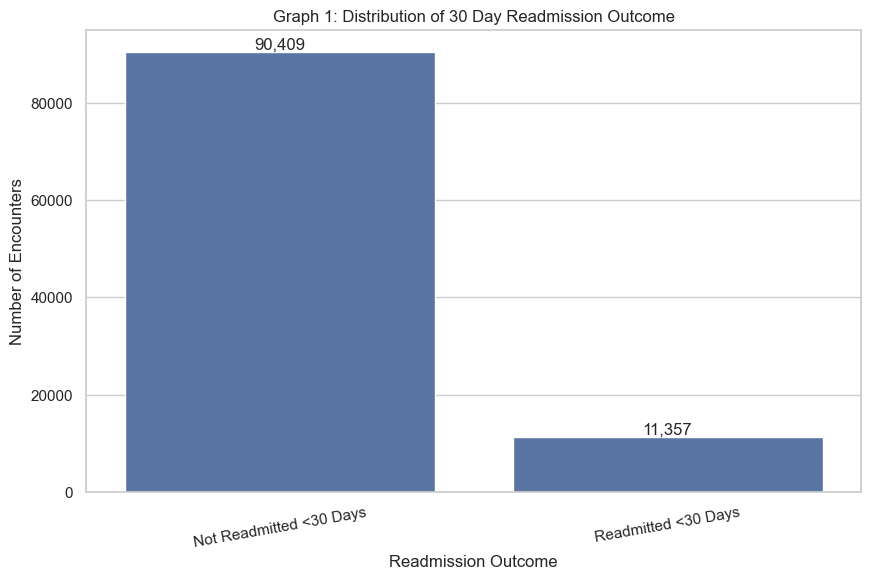

In [5]:
# Count the number of observations in each readmission category so the notebook can visualize class balance.
target_counts = df["readmit_30_label"].value_counts()

# Create a bar chart showing the number of encounters in each target class.
ax = sns.barplot(x=target_counts.index, y=target_counts.values)

# Set the title so the viewer knows the chart is about the project target distribution.
ax.set_title("Graph 1: Distribution of 30 Day Readmission Outcome")

# Label the x-axis so the categories are clearly identified.
ax.set_xlabel("Readmission Outcome")

# Label the y-axis so the chart shows that the bars represent the number of encounters.
ax.set_ylabel("Number of Encounters")

# Rotate the x-axis labels slightly so the text is easier to read in the PDF version.
plt.xticks(rotation=10)

# Add value labels on top of each bar so the exact counts are visible without estimating from the axis.
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center",
                va="bottom")

# Show the completed chart so it renders in the notebook output.
plt.show()


### Graph 2 Analysis

This graph begins to address the bias-related focus of the project by comparing estimated readmission rates across race categories. It is important because uneven patterns can suggest that later model development should include fairness-aware evaluation. At this stage, the chart does not prove discrimination or causation, but it helps flag whether demographic differences deserve closer attention.


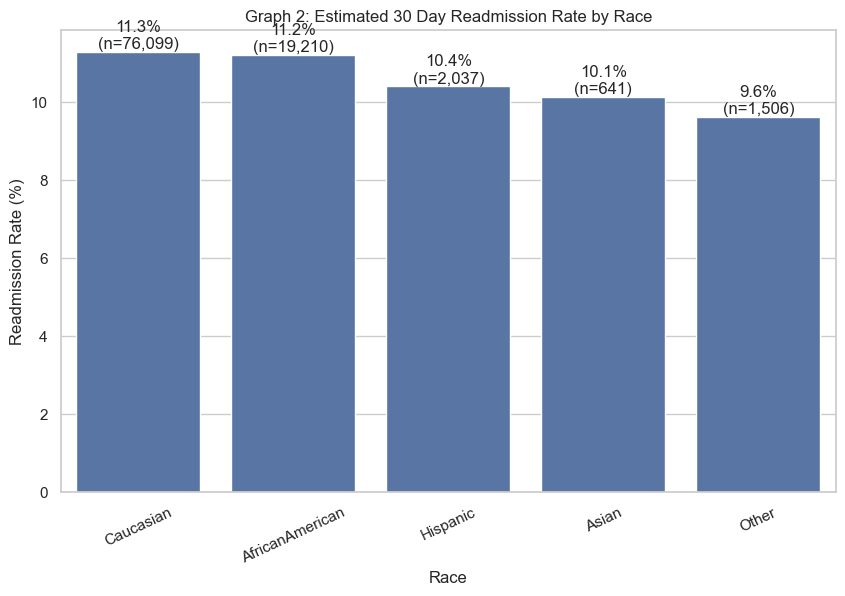

In [6]:
# Create a subset that excludes missing race values so the comparison chart reflects named race categories only.
race_df = df.dropna(subset=["race"]).copy()

# Group the data by race and calculate the average 30 day readmission flag for each group.
race_readmit = (
    race_df.groupby("race")["readmit_30_flag"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

# Convert the mean proportion to a percentage so the chart is easier to interpret in business terms.
race_readmit["readmit_rate_percent"] = race_readmit["readmit_30_flag"] * 100

# Calculate the count of observations for each race group so the sample size behind each percentage is clear.
race_counts = race_df["race"].value_counts().reset_index()
race_counts.columns = ["race", "count"]

# Merge the counts with the readmission rate table so both metrics are available together.
race_readmit = race_readmit.merge(race_counts, on="race")

# Create a bar chart showing estimated 30 day readmission rate by race.
ax = sns.barplot(data=race_readmit, x="race", y="readmit_rate_percent")

# Set the title so the reader knows this chart is examining possible differences across race groups.
ax.set_title("Graph 2: Estimated 30 Day Readmission Rate by Race")

# Label the x-axis with the demographic grouping variable being compared.
ax.set_xlabel("Race")

# Label the y-axis so the viewer knows the bars represent a percentage rate rather than raw counts.
ax.set_ylabel("Readmission Rate (%)")

# Rotate the x-axis labels so longer category names fit more cleanly.
plt.xticks(rotation=25)

# Add both percentage and sample size labels above each bar.
for i, p in enumerate(ax.patches):
    count = race_readmit.loc[i, "count"]
    ax.annotate(
        f"{p.get_height():.1f}%\n(n={count:,})",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom"
    )

# Show the chart so it is included in the notebook output.
plt.show()

In addition to the readmission rate percentages, it is important to consider the sample size of each race group when interpreting these results. Some race categories have substantially more observations than others, which means their estimated readmission rates are more stable and reliable. In contrast, smaller groups may show higher or lower percentages that are influenced by limited sample size rather than true underlying differences. Because of this, the observed variation across race groups should be interpreted with caution at this stage. In later modeling and evaluation, both outcome differences and group representation will need to be considered to avoid drawing misleading conclusions about potential bias.

### Graph 3 Analysis

This graph compares estimated 30 day readmission rates across gender categories. It is important because healthcare outcomes can vary across demographic groups, and a future classification model should be evaluated for whether its errors or predictions differ in ways that may unfairly affect patients. This chart helps establish whether that concern is worth tracking later.


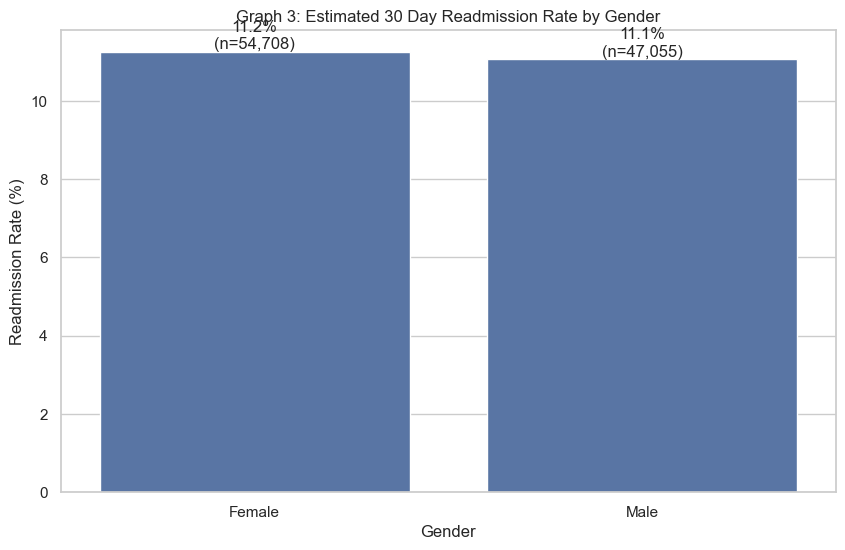

In [7]:
# Create a subset that excludes missing and invalid gender values so the comparison is based on valid recorded gender categories.
gender_df = df.dropna(subset=["gender"]).copy()
gender_df = gender_df[gender_df["gender"] != "Unknown/Invalid"].copy()

# Group the data by gender and calculate the mean of the binary readmission flag for each gender group.
gender_readmit = (
    gender_df.groupby("gender")["readmit_30_flag"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

# Calculate the count of observations for each gender group so the sample size behind each percentage is clear.
gender_counts = gender_df["gender"].value_counts().reset_index()
gender_counts.columns = ["gender", "count"]

# Merge the sample sizes with the readmission rate table.
gender_readmit = gender_readmit.merge(gender_counts, on="gender")
# Convert the mean readmission values into percentages so the chart is easier to read.
gender_readmit["readmit_rate_percent"] = gender_readmit["readmit_30_flag"] * 100

# Create a bar chart that compares estimated 30 day readmission rates by gender.
ax = sns.barplot(data=gender_readmit, x="gender", y="readmit_rate_percent")

# Add a clear chart title to explain what relationship is being visualized.
ax.set_title("Graph 3: Estimated 30 Day Readmission Rate by Gender")

# Label the x-axis with the gender categories used in the data.
ax.set_xlabel("Gender")

# Label the y-axis so the chart communicates that the metric is a percentage.
ax.set_ylabel("Readmission Rate (%)")

# Add percentage and sample size labels to each bar.
for i, p in enumerate(ax.patches):
    count = gender_readmit.loc[i, "count"]
    ax.annotate(
        f"{p.get_height():.1f}%\n(n={count:,})",
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha="center",
        va="bottom"
    )

# Show the finished chart.
plt.show()


### Graph 4 Analysis

This graph compares hospital length of stay across the two readmission outcome groups. The distributions appear fairly similar, which suggests that time in hospital may not strongly separate patients who were readmitted within 30 days from those who were not. However, length of stay may still contribute useful information when combined with other variables such as number of diagnoses, prior inpatient visits, medications, and demographic factors in later modeling.


,count,mean,std,min,25%,50%,75%,max
readmit_30_label,,,,,,,,
Not Readmitted <30 Days,90409.0,4.349224,2.976382,1.0,2.0,4.0,6.0,14.0
Readmitted <30 Days,11357.0,4.768249,3.028165,1.0,2.0,4.0,6.0,14.0


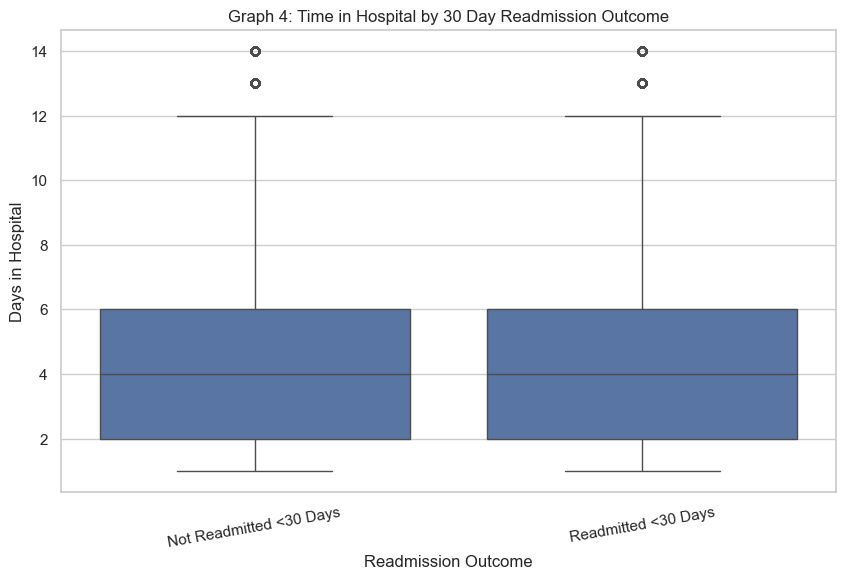

In [8]:
# Summarize time in hospital by readmission outcome to support the boxplot interpretation with numeric values.
time_summary = df.groupby("readmit_30_label")["time_in_hospital"].describe()

# Display the summary table.
display(time_summary)

# Create a boxplot to compare the distribution of hospital length of stay for the two target outcome groups.
ax = sns.boxplot(data=df, x="readmit_30_label", y="time_in_hospital")

# Add a title so the chart clearly communicates that it compares length of stay by readmission outcome.
ax.set_title("Graph 4: Time in Hospital by 30 Day Readmission Outcome")

# Label the x-axis so the two readmission groups are clearly named.
ax.set_xlabel("Readmission Outcome")

# Label the y-axis so the viewer knows the measure is the number of days spent in the hospital.
ax.set_ylabel("Days in Hospital")

# Rotate the x-axis labels slightly so they fit neatly in the chart.
plt.xticks(rotation=10)

# Show the chart.
plt.show()


### Additional Insight

This graph extends the demographic exploration by examining age-group differences. It is useful because age may be associated with both health complexity and the fairness considerations of the model. Including it gives the notebook a stronger exploratory foundation even though the assignment only requires a minimum of four graphs.

To keep the visualization readable, the chart presents only the trend in readmission rates, while a supporting table provides the exact percentage values and sample sizes for each age group. This approach allows for clearer visual interpretation while still ensuring that the underlying data can be evaluated for reliability.

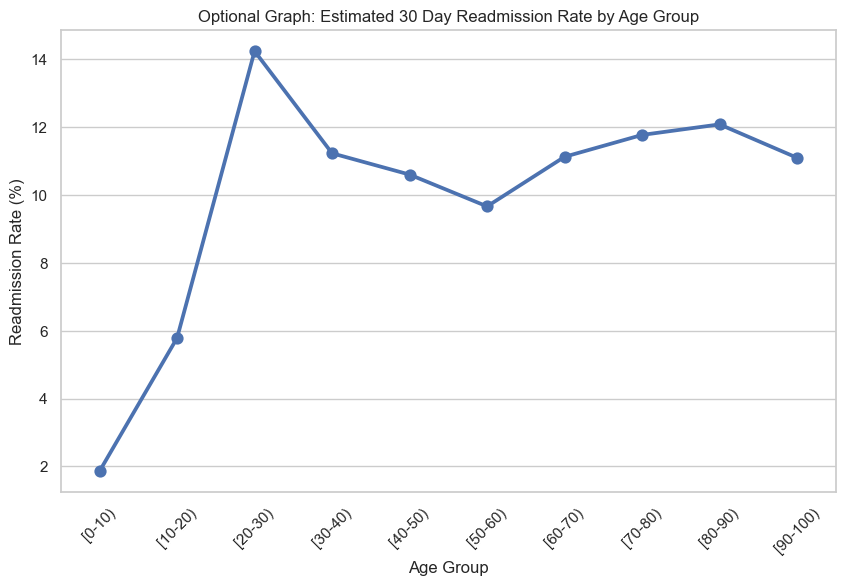

,age,readmit_rate_percent,count
0,[0-10),1.863354,161
1,[10-20),5.788712,691
2,[20-30),14.242607,1657
3,[30-40),11.231788,3775
4,[40-50),10.604027,9685
5,[50-60),9.666203,17256
6,[60-70),11.128408,22483
7,[70-80),11.773055,26068
8,[80-90),12.083503,17197
9,[90-100),11.099177,2793


In [9]:
# Group the dataset by age category and calculate the mean 30 day readmission flag for each age group.
age_readmit = (
    df.groupby("age")["readmit_30_flag"]
    .mean()
    .reset_index()
)

# Convert the readmission mean from a proportion to a percentage for easier interpretation.
age_readmit["readmit_rate_percent"] = age_readmit["readmit_30_flag"] * 100

# Count the number of encounters in each age group so the table includes sample size context.
age_counts = df["age"].value_counts().reset_index()

# Rename the count table columns so they can be merged cleanly with the readmission rate table.
age_counts.columns = ["age", "count"]

# Merge the age-group sample sizes with the age-group readmission rates.
age_readmit = age_readmit.merge(age_counts, on="age")

# Sort the age categories so the visualization follows the natural age progression.
age_readmit = age_readmit.sort_values(by="age")

# Create a point plot to show how estimated 30 day readmission rates vary across age groups.
ax = sns.pointplot(data=age_readmit, x="age", y="readmit_rate_percent")

# Add a clear title that explains the purpose of the visualization.
ax.set_title("Optional Graph: Estimated 30 Day Readmission Rate by Age Group")

# Label the x-axis with the age group categories.
ax.set_xlabel("Age Group")

# Label the y-axis so the viewer knows the values represent percentages.
ax.set_ylabel("Readmission Rate (%)")

# Rotate the age labels so they remain readable in the PDF export.
plt.xticks(rotation=45)

# Display the completed age-group readmission visualization.
plt.show()

# Display the exact readmission rate percentages and sample sizes used in the chart.
age_readmit[["age", "readmit_rate_percent", "count"]]

## Conclusion

This notebook introduced a healthcare data mining project focused on predicting 30 day hospital readmissions for diabetic patients while remaining alert to potential bias across demographic groups. The exploratory analysis established a clear business problem, defined the target variable, and used visual analysis to begin answering whether the readmission outcome varies in meaningful ways across the population.

The charts serve several purposes that connect directly to this week's readings and videos. First, they show that exploratory data analysis is not just a routine opening step. It helps clarify the structure of the prediction problem, identify possible class imbalance, and reveal relationships that may matter when selecting features and evaluation metrics. Second, the demographic charts show why responsible data mining in healthcare must go beyond overall model performance. If different groups show different observed readmission patterns, then later milestones should evaluate fairness alongside accuracy, precision, recall, and other model measures. Third, the length-of-stay chart suggests that utilization-related features may have predictive value and should be explored further in later modeling steps.

Overall, this milestone created a strong starting point for the final project. Those next steps were completed in the later sections of this final notebook. Milestone 2 cleaned and prepared the data, while Milestone 3 trained and evaluated classification models using performance metrics and fairness-aware subgroup review. These findings should be interpreted as exploratory patterns rather than evidence of causation or proof of bias.

### References

This project uses the Diabetes 130 US Hospitals dataset from the UCI Machine Learning Repository. The notebook is designed to load the dataset programmatically using the `ucimlrepo` package when available, with a local `diabetic_data.csv` fallback included for reproducibility if the live UCI connection is unavailable.

Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., & Clore, J. N. (2014). Impact of HbA1c measurement on hospital readmission rates: Analysis of 70,000 clinical database patient records. *BioMed Research International, 2014*, Article 781670. https://doi.org/10.1155/2014/781670

Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., & Clore, J. N. (2014). Diabetes 130 US hospitals for years 1999–2008 [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J

# Milestone 2: Data Preparation for Model Building

This section prepares the dataset for future machine learning. The steps are intentionally documented so the modeling choices can be reviewed later. The data preparation process avoids data snooping by not using the target outcome to decide individual feature values. The only use of the target in this section is to verify class balance and to create a stratified train-test split for future modeling.


## Recreate the Working Dataset if Needed

The following code makes the Milestone 2 section safe to run on its own. If the earlier Milestone 1 cells have already been executed, the code reuses the existing `df` DataFrame. If not, it reloads the Diabetes 130-US Hospitals dataset, replaces question-mark placeholders with missing values, and recreates the binary 30 day readmission target.


In [10]:
# Check whether the original Milestone 1 DataFrame already exists in memory.
if "df" not in globals():
    # Import Path so the notebook can check whether a local fallback CSV file exists.
    from pathlib import Path

    # Store the expected local fallback file name for environments where UCI cannot be reached.
    local_data_path = Path("diabetic_data.csv")

    # Start a try block so this section can reload the dataset from UCI when possible.
    try:
        # Fetch the diabetes hospital readmission dataset from the UCI Machine Learning Repository.
        diabetic_data = fetch_ucirepo(id=296)

        # Store the feature data in a separate DataFrame so predictors are clearly identified.
        X = diabetic_data.data.features.copy()

        # Store the target data in a separate DataFrame so the outcome is clearly identified.
        y = diabetic_data.data.targets.copy()

        # Combine the feature columns and target column into one analysis DataFrame.
        df = pd.concat([X, y], axis=1)

        # Document that the live UCI loading path worked.
        print("Dataset reloaded directly from UCI.")

    # Catch connection-related or environment-related errors from the UCI loading path.
    except Exception as error:
        # Print the original error so the notebook documents why the fallback path is being used.
        print("UCI reload failed. Original error:", error)

        # Check whether the local fallback CSV file exists in the same folder as the notebook.
        if local_data_path.exists():
            # Load the local CSV file when the live UCI connection is unavailable.
            df = pd.read_csv(local_data_path, low_memory=False)

            # Document that the local fallback file was used.
            print("Dataset reloaded from local diabetic_data.csv fallback file.")

        # Stop with a clear message if neither loading method works.
        else:
            # Raise a helpful error explaining what file is needed.
            raise FileNotFoundError("The dataset could not be loaded from UCI and diabetic_data.csv was not found in the notebook folder.")

    # Replace question-mark placeholders with true missing values so pandas can recognize them.
    df = df.replace("?", np.nan)

# Create the binary 30 day readmission target if it does not already exist.
if "readmit_30_flag" not in df.columns:
    # Assign 1 when the original readmitted value is less than 30 days and 0 otherwise.
    df["readmit_30_flag"] = np.where(df["readmitted"] == "<30", 1, 0)

# Create a separate working copy so Milestone 2 changes do not overwrite the original DataFrame.
model_df = df.copy()

# Display the shape of the working DataFrame so the notebook documents the starting point for preparation.
print("Working dataset shape for Milestone 2:", model_df.shape)

# Display the first few rows so the notebook verifies that the working DataFrame was created correctly.
model_df.head()


Working dataset shape for Milestone 2: (101766, 50)


,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,...,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,readmit_30_flag,readmit_30_label
0,Caucasian,Female,[0-10),NaN,6,25,1,1,<NA>,Pediatrics-Endocrinology,...,No,No,No,No,No,No,No,NO,0,Not Readmitted <30 Days
1,Caucasian,Female,[10-20),NaN,1,1,7,3,<NA>,NaN,...,No,No,No,No,No,Ch,Yes,>30,0,Not Readmitted <30 Days
2,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,<NA>,NaN,...,No,No,No,No,No,No,Yes,NO,0,Not Readmitted <30 Days
3,Caucasian,Male,[30-40),NaN,1,1,7,2,<NA>,NaN,...,No,No,No,No,No,Ch,Yes,NO,0,Not Readmitted <30 Days
4,Caucasian,Male,[40-50),NaN,1,1,7,1,<NA>,NaN,...,No,No,No,No,No,Ch,Yes,NO,0,Not Readmitted <30 Days


This setup block protects reproducibility. It makes sure the same source data and the same binary target are available even if the notebook is opened fresh. The target distribution is displayed again because the professor specifically warned that imbalance could create modeling problems. Seeing the distribution before feature preparation helps justify later use of stratified splitting, class weights, and evaluation metrics beyond accuracy.

The UCI import function produces a mixed-type warning for `payer_code` during the dataset loading step. This warning occurs before the notebook can manually convert the column type. Because `payer_code` represents categorical payer information rather than a numeric measurement, the warning was suppressed during import and the column was explicitly converted to a string datatype after loading.


## Review Missingness Before Cleaning

The following code summarizes missing values by count and percentage. This is important because missing data should not be removed blindly. The cleaning decision depends on whether a column has limited missingness, heavy missingness, meaningful missingness, or missing values that represent a known healthcare workflow status such as a test not being performed.


In [11]:
# Count missing values in each column so the notebook can identify columns that require cleaning.
missing_count = model_df.isna().sum()

# Calculate the percentage of missing values in each column so large and small missingness patterns can be compared fairly.
missing_percent = (missing_count / len(model_df) * 100).round(2)

# Combine missing counts and percentages into one summary table for easier review.
missing_table = pd.DataFrame({"missing_count": missing_count, "missing_percent": missing_percent})

# Keep only columns with at least one missing value so the output stays focused.
missing_table = missing_table[missing_table["missing_count"] > 0]

# Sort the table from highest to lowest missing percentage so the largest issues appear first.
missing_table = missing_table.sort_values(by="missing_percent", ascending=False)

# Display the missingness summary table for documentation.
display(missing_table)


,missing_count,missing_percent
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


This block documents the missing data problem before any cleaning occurs. In this dataset, some missingness is too large or too structurally important to treat as ordinary random missing data. For example, `weight` is commonly missing and is not reliable enough for a first modeling dataset. Other fields such as lab result indicators can be kept by treating missingness as a meaningful category because the absence of a test result may reflect care patterns.


## Drop Features That Are Not Useful for Model Building

The next code block removes fields that are not appropriate for the first modeling dataset. The removal decisions are documented in a table before the columns are dropped. This keeps the process transparent and prevents unexplained feature loss.


In [12]:
# Create a dictionary describing columns to remove and the reason each one is not useful for this modeling stage.
drop_reasons = {
    "encounter_id": "Encounter identifier; useful for tracking records but not a generalizable predictor.",
    "patient_nbr": "Patient identifier; may create leakage or memorization because some patients have repeated encounters.",
    "readmitted": "Original multi-class outcome; removed after creating the binary target to avoid target leakage.",
    "weight": "Extremely high missingness; not reliable enough for the first model without stronger collection support.",
    "payer_code": "High missingness and administrative payer detail; may introduce insurance-related bias concerns in the first model.",
    "medical_specialty": "High missingness and high cardinality; would create many sparse dummy variables at this stage.",
    "examide": "Near-constant medication field that provides no meaningful separation for modeling.",
    "citoglipton": "Near-constant medication field that provides no meaningful separation for modeling."
}

# Keep only the drop columns that actually exist in the current DataFrame to avoid errors if the dataset schema changes.
columns_to_drop = [column for column in drop_reasons.keys() if column in model_df.columns]

# Convert the drop decisions into a DataFrame so the notebook clearly explains each removal.
drop_decision_table = pd.DataFrame(
    [(column, drop_reasons[column]) for column in columns_to_drop],
    columns=["column_removed", "reason"]
)

# Display the feature removal table before actually dropping the columns.
display(drop_decision_table)

# Drop the selected columns from the working DataFrame.
model_df = model_df.drop(columns=columns_to_drop)

# Display the updated shape so the notebook documents how many columns remain after feature removal.
print("Shape after dropping non-useful or risky features:", model_df.shape)


,column_removed,reason
0,readmitted,Original multi-class outcome; removed after cr...
1,weight,Extremely high missingness; not reliable enoug...
2,payer_code,High missingness and administrative payer deta...
3,medical_specialty,High missingness and high cardinality; would c...
4,examide,Near-constant medication field that provides n...
5,citoglipton,Near-constant medication field that provides n...


Shape after dropping non-useful or risky features: (101766, 44)


This step removes identifiers, direct outcome leakage, very sparse fields, and fields that are not suitable for a first modeling dataset. If identifier fields such as `encounter_id` or `patient_nbr` are present in a version of the dataset, they are especially important to remove because identifiers can allow a model to memorize records instead of learning general patterns. The original `readmitted` field must also be removed because the project target has already been derived from it.


## Data Selection and Basic Record Filtering

The following block performs limited row-level selection. The goal is not to drop rows for convenience, but to remove records with invalid demographic labels that could distort later fairness review. This filtering is intentionally narrow.


In [13]:
# Store the number of rows before filtering so the notebook can document the impact of selection.
rows_before_filtering = len(model_df)

# Remove records with invalid gender values because they are not interpretable for demographic comparison.
model_df = model_df[model_df["gender"] != "Unknown/Invalid"].copy()

# Store the number of rows after filtering so the notebook can calculate how many records were removed.
rows_after_filtering = len(model_df)

# Calculate the number of removed rows so the filtering impact is transparent.
rows_removed = rows_before_filtering - rows_after_filtering

# Print the filtering result so the notebook documents the selection step.
print("Rows before filtering:", rows_before_filtering)

# Print the number of rows after filtering.
print("Rows after filtering:", rows_after_filtering)

# Print the number of rows removed by the filtering step.
print("Rows removed:", rows_removed)


Rows before filtering: 101766
Rows after filtering: 101763
Rows removed: 3


This selection step removes only records with an invalid gender label. The decision is narrow because the assignment cautions against dropping rows or columns without justification. Records are not dropped simply because they contain missing values. Missing values are handled in later steps with explicit categories or engineered flags.


## Handle Missing Data Without Blindly Dropping Rows

This code handles missing values in a way that fits the meaning of the variables. Race is filled with `Missing` so the row can remain available while still preserving the fact that race was not recorded. Lab result fields are filled with `Not measured` because a missing lab result may be a meaningful care-process signal. Diagnosis fields are filled with `Missing diagnosis` so they can be categorized later.


In [14]:
# Create a missingness flag for race so the model can retain whether race was absent rather than silently hiding it.
model_df["race_missing_flag"] = np.where(model_df["race"].isna(), 1, 0)

# Fill missing race values with an explicit category so rows are not dropped due to missing race.
model_df["race"] = model_df["race"].fillna("Missing")

# Fill missing max_glu_serum values as Not measured because no result may indicate the test was not performed.
model_df["max_glu_serum"] = model_df["max_glu_serum"].fillna("Not measured")

# Fill missing A1Cresult values as Not measured because no result may indicate the test was not performed.
model_df["A1Cresult"] = model_df["A1Cresult"].fillna("Not measured")

# Fill missing diag_1 values with a specific label so diagnosis extraction can handle them safely.
model_df["diag_1"] = model_df["diag_1"].fillna("Missing diagnosis")

# Fill missing diag_2 values with a specific label so diagnosis extraction can handle them safely.
model_df["diag_2"] = model_df["diag_2"].fillna("Missing diagnosis")

# Fill missing diag_3 values with a specific label so diagnosis extraction can handle them safely.
model_df["diag_3"] = model_df["diag_3"].fillna("Missing diagnosis")

# Recalculate missing values after the cleaning step so the notebook can verify the result.
remaining_missing = model_df.isna().sum().sort_values(ascending=False)

# Display any columns that still contain missing values after the targeted cleaning process.
display(remaining_missing[remaining_missing > 0])


Series([], dtype: int64)

This block keeps records instead of deleting them. For healthcare data, missingness can be meaningful. A lab result that is not present may mean the test was not ordered, not simply that the value was lost. By creating explicit missing categories and flags, the data preparation process preserves information while making the dataset usable for machine learning.


## Transform Ordered and Clinical Features

The next block transforms variables that have useful order or clinical meaning. Age ranges are converted to approximate midpoint values, medication change fields are converted into numeric direction values, and selected yes/no columns are converted into binary indicators.


In [15]:
# Create a dictionary that maps each age range to an approximate midpoint value.
age_midpoint_map = {
    "[0-10)": 5,
    "[10-20)": 15,
    "[20-30)": 25,
    "[30-40)": 35,
    "[40-50)": 45,
    "[50-60)": 55,
    "[60-70)": 65,
    "[70-80)": 75,
    "[80-90)": 85,
    "[90-100)": 95
}

# Map age ranges to midpoint values so age can be used as an ordered numeric feature.
model_df["age_midpoint"] = model_df["age"].map(age_midpoint_map)

# Create a dictionary that converts medication change directions into numeric values.
medication_direction_map = {"No": 0, "Steady": 1, "Up": 2, "Down": -1}

# Identify medication columns that use the common No, Steady, Up, and Down coding pattern.
medication_columns = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "insulin", "glyburide-metformin", "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone"
]

# Keep only medication columns that are present in the DataFrame to make the notebook robust.
medication_columns = [column for column in medication_columns if column in model_df.columns]

# Loop through each medication column so the same transformation is applied consistently.
for column in medication_columns:
    # Create a numeric medication direction feature for the current medication column.
    model_df[f"{column}_direction"] = model_df[column].map(medication_direction_map).fillna(0)

# Convert the change column to a binary flag where 1 means a medication change occurred.
model_df["medication_changed_flag"] = np.where(model_df["change"] == "Ch", 1, 0)

# Convert the diabetesMed column to a binary flag where 1 means a diabetes medication was prescribed.
model_df["diabetes_med_flag"] = np.where(model_df["diabetesMed"] == "Yes", 1, 0)

# Convert insulin status to a binary flag where 1 means insulin was used or adjusted.
model_df["insulin_used_flag"] = np.where(model_df["insulin"] == "No", 0, 1)

# Display a preview of the transformed features to verify the new columns were created correctly.
display(model_df[["age", "age_midpoint", "change", "medication_changed_flag", "diabetesMed", "diabetes_med_flag", "insulin", "insulin_used_flag"]].head())


,age,age_midpoint,change,medication_changed_flag,diabetesMed,diabetes_med_flag,insulin,insulin_used_flag
0,[0-10),5,No,0,No,0,No,0
1,[10-20),15,Ch,1,Yes,1,Up,1
2,[20-30),25,No,0,Yes,1,No,0
3,[30-40),35,Ch,1,Yes,1,Up,1
4,[40-50),45,Ch,1,Yes,1,Steady,1


These transformations make the data easier for a future model to interpret. Age originally appears as text ranges, so midpoint values preserve its natural order. Medication columns contain direction-like information, so numeric direction features allow future models to use whether a medication was stopped, steady, increased, or decreased. The original categorical versions are still available until the final dummy-variable step.


## Engineer New Useful Features

The following code creates new features that may better represent patient complexity and prior utilization. These features are based on clinical and operational reasoning rather than the target outcome, which helps avoid data snooping.


In [16]:
# Create a total prior utilization feature by adding outpatient, emergency, and inpatient visit counts.
model_df["prior_utilization_total"] = model_df["number_outpatient"] + model_df["number_emergency"] + model_df["number_inpatient"]

# Create a binary flag showing whether the patient had any prior inpatient visits.
model_df["prior_inpatient_flag"] = np.where(model_df["number_inpatient"] > 0, 1, 0)

# Create a binary flag showing whether the patient had any emergency visits.
model_df["prior_emergency_flag"] = np.where(model_df["number_emergency"] > 0, 1, 0)

# Create a medication intensity feature by dividing the number of medications by the hospital length of stay.
model_df["medications_per_day"] = model_df["num_medications"] / model_df["time_in_hospital"].replace(0, np.nan)

# Fill any unexpected missing values in medications_per_day with 0 so the feature is model-ready.
model_df["medications_per_day"] = model_df["medications_per_day"].fillna(0)

# Create a diagnosis complexity bucket to make number of diagnoses easier to interpret.
model_df["diagnosis_count_bucket"] = pd.cut(
    model_df["number_diagnoses"],
    bins=[0, 3, 6, 9, np.inf],
    labels=["Low", "Moderate", "High", "Very high"],
    include_lowest=True
)

# Display the engineered feature summary so the notebook documents the new variables.
display(model_df[["prior_utilization_total", "prior_inpatient_flag", "prior_emergency_flag", "medications_per_day", "diagnosis_count_bucket"]].describe(include="all"))


,prior_utilization_total,prior_inpatient_flag,prior_emergency_flag,medications_per_day,diagnosis_count_bucket
count,101763.000000,101763.000000,101763.000000,101763.000000,101763
unique,NaN,NaN,NaN,NaN,4
top,NaN,NaN,NaN,NaN,High
freq,NaN,NaN,NaN,NaN,70482
mean,1.202795,0.335446,0.111858,5.074314,NaN
std,2.291805,0.472148,0.315193,3.825718,NaN
min,0.000000,0.000000,0.000000,0.083333,NaN
25%,0.000000,0.000000,0.000000,2.600000,NaN
50%,0.000000,0.000000,0.000000,4.000000,NaN
75%,2.000000,1.000000,0.000000,6.166667,NaN


These engineered features may help the future model capture patient complexity. Prior utilization summarizes recent care use. Emergency and inpatient flags identify whether the patient had earlier acute care activity. Medications per day provides a rough measure of medication intensity during the encounter. Diagnosis count buckets convert a raw count into a more interpretable level of clinical complexity.


## Extract Diagnosis Categories

The diagnosis fields contain ICD-style codes and some text categories. Instead of creating thousands of sparse dummy variables from individual diagnosis codes, this notebook extracts broader diagnosis groups. This keeps the feature set more manageable and reduces overfitting risk.


In [17]:
# Define a function that groups diagnosis codes into broad clinical categories.
def categorize_diagnosis(code):
    # Convert the diagnosis code to a string so numeric and text codes can be handled consistently.
    code_text = str(code)

    # Return Missing when the diagnosis value was filled as missing earlier.
    if code_text == "Missing diagnosis":
        return "Missing diagnosis"

    # Return Diabetes when the diagnosis code begins with the diabetes ICD-9 prefix 250.
    if code_text.startswith("250"):
        return "Diabetes"

    # Return Circulatory when the original text label already indicates a circulatory diagnosis.
    if code_text.lower() == "circulatory":
        return "Circulatory"

    # Return Respiratory when the original text label already indicates a respiratory diagnosis.
    if code_text.lower() == "respiratory":
        return "Respiratory"

    # Return Digestive when the original text label already indicates a digestive diagnosis.
    if code_text.lower() == "digestive":
        return "Digestive"

    # Try to convert the diagnosis code into a numeric value for ICD-9 range grouping.
    try:
        # Convert the text code to a float so codes with decimals can still be categorized.
        numeric_code = float(code_text)
    except ValueError:
        # Return Other when the code cannot be converted or matched to a known text category.
        return "Other"

    # Group ICD-9 codes from 390 to 459 as circulatory diagnoses.
    if 390 <= numeric_code <= 459:
        return "Circulatory"

    # Group ICD-9 code 785 as circulatory because it is commonly included in this dataset's circulatory grouping.
    if numeric_code == 785:
        return "Circulatory"

    # Group ICD-9 codes from 460 to 519 as respiratory diagnoses.
    if 460 <= numeric_code <= 519:
        return "Respiratory"

    # Group ICD-9 code 786 as respiratory because it is commonly included in this dataset's respiratory grouping.
    if numeric_code == 786:
        return "Respiratory"

    # Group ICD-9 codes from 520 to 579 as digestive diagnoses.
    if 520 <= numeric_code <= 579:
        return "Digestive"

    # Group ICD-9 code 787 as digestive because it is commonly included in this dataset's digestive grouping.
    if numeric_code == 787:
        return "Digestive"

    # Group ICD-9 codes from 800 to 999 as injury-related diagnoses.
    if 800 <= numeric_code <= 999:
        return "Injury"

    # Return Other for all diagnosis codes that do not fall into the selected broad categories.
    return "Other"

# Apply the diagnosis categorization function to the primary diagnosis column.
model_df["diag_1_category"] = model_df["diag_1"].apply(categorize_diagnosis)

# Apply the diagnosis categorization function to the secondary diagnosis column.
model_df["diag_2_category"] = model_df["diag_2"].apply(categorize_diagnosis)

# Apply the diagnosis categorization function to the third diagnosis column.
model_df["diag_3_category"] = model_df["diag_3"].apply(categorize_diagnosis)

# Display the primary diagnosis category distribution to verify the extraction result.
display(model_df["diag_1_category"].value_counts())


diag_1_category
Other                31679
Circulatory          30436
Respiratory          14423
Digestive             9475
Diabetes              8757
Injury                6972
Missing diagnosis       21
Name: count, dtype: int64

This extraction step turns raw diagnosis codes into broader groups that are more practical for modeling. This avoids allowing thousands of unique diagnosis codes to dominate the model with sparse categories. It also creates a more interpretable feature set for later analysis of which clinical categories are associated with readmission risk.


## Prepare Features and Target for Modeling

The following block separates the target from the predictors, removes raw columns that have already been transformed, and creates a final feature table. Race and gender are retained for now because the project is specifically about potential healthcare bias. In a final modeling notebook, the project can compare model performance with and without demographic fields.


In [18]:
# Store the binary target in a separate Series so predictors and outcome are clearly separated.
y_model = model_df["readmit_30_flag"].copy()

# Create a list of raw columns to remove because transformed versions or safer summaries already exist.
raw_columns_to_remove = [
    "diag_1", "diag_2", "diag_3", "age", "change", "diabetesMed"
]

# Add the original medication columns to the removal list because numeric direction versions were already created.
raw_columns_to_remove = raw_columns_to_remove + medication_columns

# Create a list of target-related columns that must not be used as predictors.
target_leakage_columns = [
    "readmitted",
    "readmit_30_flag",
    "readmit_30_label"
]

# Combine raw transformed columns and target-related columns into one removal list.
columns_to_remove_from_predictors = raw_columns_to_remove + target_leakage_columns

# Keep only columns that actually exist in the DataFrame.
columns_to_remove_from_predictors = [
    column for column in columns_to_remove_from_predictors if column in model_df.columns
]

# Create the predictor DataFrame by removing target-related and raw transformed columns.
X_model = model_df.drop(columns=columns_to_remove_from_predictors)

# Check whether any readmission-related columns accidentally remain.
leakage_check = [column for column in X_model.columns if "readmit" in column.lower()]

# Print the result. This should be an empty list.
print("Target-related columns remaining in predictors:", leakage_check)

# Display the predictor shape before dummy variables.
print("Predictor shape before dummy variables:", X_model.shape)

# Preview the predictors.
display(X_model.head())

Target-related columns remaining in predictors: []
Predictor shape before dummy variables: (101763, 49)


,race,gender,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,...,diabetes_med_flag,insulin_used_flag,prior_utilization_total,prior_inpatient_flag,prior_emergency_flag,medications_per_day,diagnosis_count_bucket,diag_1_category,diag_2_category,diag_3_category
0,Caucasian,Female,6,25,1,1,41,0,1,0,...,0,0,0,0,0,1.0,Low,Diabetes,Missing diagnosis,Missing diagnosis
1,Caucasian,Female,1,1,7,3,59,0,18,0,...,1,1,0,0,0,6.0,High,Other,Diabetes,Other
2,AfricanAmerican,Female,1,1,7,2,11,5,13,2,...,1,0,3,1,0,6.5,Moderate,Other,Diabetes,Other
3,Caucasian,Male,1,1,7,2,44,1,16,0,...,1,1,0,0,0,8.0,High,Other,Diabetes,Circulatory
4,Caucasian,Male,1,1,7,1,51,0,8,0,...,1,1,0,0,0,8.0,Moderate,Other,Other,Diabetes


This step also removes all target-related fields from the predictor set. The original `readmitted` field, the binary target `readmit_30_flag`, and the display label `readmit_30_label` are excluded because they describe the outcome the model is supposed to predict. Keeping any of these fields in the predictors would create target leakage, causing the model to appear unrealistically accurate during evaluation.


## Create Dummy Variables

Most machine learning algorithms require numeric input. The following block converts categorical fields into dummy variables while leaving numeric fields unchanged. The result is a fully numeric dataset that can be used in a future classification model.


In [19]:
# Identify categorical columns including pandas string datatypes.
# Adding "string" prevents future pandas compatibility warnings.
categorical_columns = X_model.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Identify numeric columns by selecting all non-categorical columns.
numeric_columns = X_model.select_dtypes(exclude=["object", "category"]).columns.tolist()

# Print the number of categorical columns so the notebook documents what will be dummy encoded.
print("Number of categorical columns to dummy encode:", len(categorical_columns))

# Print the number of numeric columns so the notebook documents what will remain numeric.
print("Number of numeric columns retained:", len(numeric_columns))

# Create dummy variables for categorical columns and drop the first level to reduce redundant columns.
X_encoded = pd.get_dummies(X_model, columns=categorical_columns, drop_first=True, dtype=int)

# Display the encoded feature shape so the notebook shows the model-ready dataset size.
print("Predictor shape after dummy variables:", X_encoded.shape)

# Verify that all encoded columns are numeric so the data is ready for model building.
print("All columns numeric:", all(pd.api.types.is_numeric_dtype(X_encoded[column]) for column in X_encoded.columns))

# Display a preview of the encoded modeling table.
display(X_encoded.head())


Number of categorical columns to dummy encode: 8
Number of numeric columns retained: 41
Predictor shape after dummy variables: (101763, 74)
All columns numeric: True


,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,...,diag_2_category_Injury,diag_2_category_Missing diagnosis,diag_2_category_Other,diag_2_category_Respiratory,diag_3_category_Diabetes,diag_3_category_Digestive,diag_3_category_Injury,diag_3_category_Missing diagnosis,diag_3_category_Other,diag_3_category_Respiratory
0,6,25,1,1,41,0,1,0,0,0,...,0,1,0,0,0,0,0,1,0,0
1,1,1,7,3,59,0,18,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,1,1,7,2,11,5,13,2,0,1,...,0,0,0,0,0,0,0,0,1,0
3,1,1,7,2,44,1,16,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,1,7,1,51,0,8,0,0,0,...,0,0,1,0,1,0,0,0,0,0


Dummy variable creation is necessary because categorical values such as race, gender, admission type, discharge disposition, and diagnosis category cannot be passed directly into most machine learning models. The encoded dataset is now numeric and ready for future model building. Dropping the first level helps reduce redundant dummy columns while preserving the categorical information.


## Stratified Split and Imbalance Planning

The final preparation step creates a stratified train-test split and class weights for future model training. This does not build the final model yet. It prepares the data so that later modeling can handle the imbalanced target more responsibly.


In [20]:
# Import train_test_split so the prepared data can be separated into training and testing sets.
from sklearn.model_selection import train_test_split

# Import compute_class_weight so the notebook can calculate weights for the imbalanced target.
from sklearn.utils.class_weight import compute_class_weight

# Split the encoded predictors and target into training and testing sets with stratification to preserve class balance.
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_model,
    test_size=0.20,
    random_state=42,
    stratify=y_model
)

# Calculate class weights so future models can give more attention to the minority readmission class.
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

# Convert the class weights into a dictionary format accepted by many scikit-learn classifiers.
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

# Display the training target distribution to verify that stratification preserved the imbalance pattern.
print("Training target distribution (%):")

# Print the percent distribution for the training target.
print(y_train.value_counts(normalize=True).mul(100).round(2))

# Display the testing target distribution to verify that the holdout set has a similar outcome distribution.
print("Testing target distribution (%):")

# Print the percent distribution for the testing target.
print(y_test.value_counts(normalize=True).mul(100).round(2))

# Display the calculated class weights for future model training.
print("Class weights for future modeling:", class_weight_dict)


Training target distribution (%):
readmit_30_flag
0    88.84
1    11.16
Name: proportion, dtype: float64
Testing target distribution (%):
readmit_30_flag
0    88.84
1    11.16
Name: proportion, dtype: float64
Class weights for future modeling: {0: np.float64(0.5628145567169958), 1: np.float64(4.479969183359014)}


This block directly addresses the instructor's concern about class imbalance. Stratified splitting keeps the minority readmission class represented in both training and testing data. Class weights provide a practical option for future classifiers so that the model does not simply favor the majority class. In the modeling milestone, accuracy should not be used alone because a high-accuracy model could still miss many true readmissions.


## Final Prepared Dataset Summary

The following block creates a concise summary of the prepared data. This gives the final notebook reader a clear checkpoint showing that Milestone 2 produced a model-ready feature matrix, target vector, train-test split, dummy variables, engineered features, and imbalance plan.


In [21]:
# Create a summary table containing key preparation outcomes.
preparation_summary = pd.DataFrame({
    "item": [
        "Rows in prepared feature matrix",
        "Columns in prepared feature matrix",
        "Training rows",
        "Testing rows",
        "Positive target rate overall",
        "Number of engineered or transformed features noted"
    ],
    "value": [
        X_encoded.shape[0],
        X_encoded.shape[1],
        X_train.shape[0],
        X_test.shape[0],
        round(y_model.mean() * 100, 2),
        "Age midpoint, diagnosis categories, utilization flags, medication flags, medication directions"
    ]
})

# Display the preparation summary table for final documentation.
display(preparation_summary)

# Save the prepared modeling data to a CSV file for optional local review if needed.
prepared_output = X_encoded.copy()

# Add the target back to the prepared output so the optional file contains both predictors and outcome.
prepared_output["readmit_30_flag"] = y_model.values

# Write the prepared dataset to CSV using an assignment-friendly file name.
prepared_output.to_csv("shelia_howard_dsc550_milestone2_prepared_data.csv", index=False)

# Print a confirmation message so the notebook documents that the prepared dataset file was created.
print("Prepared data saved as shelia_howard_dsc550_milestone2_prepared_data.csv")


,item,value
0,Rows in prepared feature matrix,101763
1,Columns in prepared feature matrix,74
2,Training rows,81410
3,Testing rows,20353
4,Positive target rate overall,11.16
5,Number of engineered or transformed features n...,"Age midpoint, diagnosis categories, utilizatio..."


Prepared data saved as shelia_howard_dsc550_milestone2_prepared_data.csv


This final checkpoint confirms that the notebook now has a model-ready dataset. The prepared data includes feature selection, missing value treatment, transformed features, engineered features, dummy variables, and a target-aware but non-snooping split strategy. The optional CSV export can be submitted with the notebook if the instructor requires a data file, but the notebook still documents how the data was prepared from the original UCI source.


## Milestone 2 Conclusion

Milestone 2 prepared the healthcare readmission dataset for the future model building and evaluation phase. The notebook began by preserving the original Milestone 1 context, then created a clean working dataset, reviewed missingness, dropped non-useful or risky features, performed limited record selection, handled missing values without blindly deleting rows, transformed ordered and clinical fields, engineered new features, extracted diagnosis categories, created dummy variables, and prepared a stratified train-test split.

The most important modeling insight from this milestone is that the project must account for target imbalance. Since the 30 day readmission class is much smaller than the non-readmission class, future model evaluation should focus on recall, precision, F1-score, ROC-AUC, and PR-AUC rather than accuracy alone. This is especially important in a healthcare setting because failing to identify high-risk patients could reduce the usefulness of the model.

This week's data preparation focus connects directly to the practical machine learning workflow. Before a model can be trusted, the dataset needs to be cleaned, structured, and transformed in a way that fits the business problem. For this project, responsible preparation also means thinking about potential bias. Race and gender were retained for later fairness review, while identifiers and high-risk leakage fields were removed. The resulting dataset is ready for the next milestone, where classification models can be trained and evaluated using metrics that reflect both performance and responsible healthcare decision support.


# Milestone 3: Model Selection, Model Building, and Model Evaluation

Milestone 3 begins the model building phase of the project. The goal is to train and evaluate classification models that predict whether a diabetic hospital encounter resulted in readmission within 30 days. Because the positive class is much smaller than the negative class, this section does not rely on accuracy alone. Instead, the evaluation emphasizes recall, precision, F1-score, ROC-AUC, PR-AUC, and confusion matrices.

This modeling approach connects directly to the professor's Milestone 1 feedback about target imbalance. In a healthcare setting, a model that performs well only by predicting the majority class is not very useful. The model must be judged on whether it can identify patients who may need additional follow-up support while still being interpreted carefully because prediction is not the same as causation.


## Milestone 3 Modeling Plan

This section uses the prepared dataset from Milestone 2. The target is `readmit_30_flag`, where 1 means the encounter resulted in readmission within 30 days and 0 means it did not.

The modeling plan includes four steps:

1. Train a simple baseline model so later models can be compared against a basic reference point.
2. Train a class-weighted logistic regression model because it is interpretable and appropriate for binary classification.
3. Train a class-weighted random forest model because it can capture nonlinear relationships and interactions across healthcare utilization, demographic, and clinical features.
4. Evaluate model performance using metrics that are more useful than accuracy for an imbalanced healthcare outcome.

Logistic regression is useful as an interpretable baseline model, while random forest provides a stronger comparison model that may detect patterns not captured by a linear approach. Both models use class imbalance handling so the minority readmission class receives more attention during training.


In [22]:
# Import pandas so model results can be organized into readable tables.
import pandas as pd

# Import numpy so the notebook can perform numeric calculations for model evaluation.
import numpy as np

# Import matplotlib so the notebook can create evaluation charts.
import matplotlib.pyplot as plt

# Import seaborn so the notebook can create readable confusion matrix visualizations.
import seaborn as sns

# Import DummyClassifier so the notebook can create a simple baseline model for comparison.
from sklearn.dummy import DummyClassifier

# Import LogisticRegression so the notebook can train an interpretable binary classification model.
from sklearn.linear_model import LogisticRegression

# Import RandomForestClassifier so the notebook can train a nonlinear tree-based classification model.
from sklearn.ensemble import RandomForestClassifier

# Import Pipeline so preprocessing and model training can be handled as one repeatable workflow.
from sklearn.pipeline import Pipeline

# Import StandardScaler so numeric values can be scaled before logistic regression.
from sklearn.preprocessing import StandardScaler

# Import evaluation metrics that are appropriate for a binary and imbalanced classification problem.
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

# Import classification_report so the notebook can display precision, recall, and F1-score by class.
from sklearn.metrics import classification_report

# Import confusion_matrix so the notebook can compare actual and predicted classes.
from sklearn.metrics import confusion_matrix

# Import RocCurveDisplay so the notebook can visualize model separation across thresholds.
from sklearn.metrics import RocCurveDisplay

# Import PrecisionRecallDisplay so the notebook can visualize performance for the minority readmission class.
from sklearn.metrics import PrecisionRecallDisplay

# Set the plotting style so all evaluation charts use a consistent visual format.
sns.set_theme(style="whitegrid")

# Set the default figure size so chart labels remain readable in notebook and PDF output.
plt.rcParams["figure.figsize"] = (10, 6)


This code block imports the libraries needed for Milestone 3 model building and evaluation. The imports include baseline modeling, logistic regression, random forest classification, scaling, model pipelines, and several evaluation metrics. This step matters because the professor's instructions ask for model selection, model building, and model evaluation, and each of those steps requires tools that are appropriate for a binary classification problem with class imbalance.


## Confirm the Prepared Modeling Data

Before training any model, the notebook confirms that the prepared training and testing datasets from Milestone 2 are available. This protects the modeling section from running on incomplete data and gives the reader a checkpoint before model fitting begins.


In [23]:
# Create a list of required modeling objects from Milestone 2.
required_objects = ["X_train", "X_test", "y_train", "y_test", "class_weight_dict"]

# Check each required object to see whether it already exists in notebook memory.
missing_objects = [object_name for object_name in required_objects if object_name not in globals()]

# Stop the notebook with a clear message if a required Milestone 2 object is missing.
if missing_objects:
    raise RuntimeError(f"Run the Milestone 2 preparation cells before Milestone 3. Missing objects: {missing_objects}")

# Print the training feature shape so the reader can see how many rows and columns are used for training.
print("Training feature shape:", X_train.shape)

# Print the testing feature shape so the reader can see how many rows and columns are reserved for evaluation.
print("Testing feature shape:", X_test.shape)

# Print the class weights calculated in Milestone 2 so the imbalance handling strategy is documented.
print("Class weights used for imbalance handling:", class_weight_dict)

# Display the training target distribution so the reader can verify the minority class is still represented.
print("Training target distribution (%):")

# Calculate and print the percentage of each target class in the training data.
print(y_train.value_counts(normalize=True).mul(100).round(2))

# Display the testing target distribution so the reader can verify stratification carried into the holdout set.
print("Testing target distribution (%):")

# Calculate and print the percentage of each target class in the testing data.
print(y_test.value_counts(normalize=True).mul(100).round(2))


Training feature shape: (81410, 74)
Testing feature shape: (20353, 74)
Class weights used for imbalance handling: {0: np.float64(0.5628145567169958), 1: np.float64(4.479969183359014)}
Training target distribution (%):
readmit_30_flag
0    88.84
1    11.16
Name: proportion, dtype: float64
Testing target distribution (%):
readmit_30_flag
0    88.84
1    11.16
Name: proportion, dtype: float64


This checkpoint confirms that the Milestone 2 preparation work successfully produced a model-ready training set, testing set, target vector, and class weighting strategy. It is important because model evaluation is only meaningful when the data split is clear and when the class imbalance issue has been carried forward into the modeling stage.


## Baseline Model

A baseline model gives the project a simple reference point. This model predicts the most frequent class and does not learn meaningful healthcare patterns. It is included so that the logistic regression and random forest models can be compared against a simple majority-class approach.


In [24]:
# Create a baseline classifier that always predicts the most frequent target class.
baseline_model = DummyClassifier(strategy="most_frequent")

# Fit the baseline model using the training predictors and training target.
baseline_model.fit(X_train, y_train)

# Use the fitted baseline model to predict the testing target values.
y_pred_baseline = baseline_model.predict(X_test)

# Calculate baseline accuracy so the notebook can show how misleading accuracy can be with imbalanced data.
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

# Calculate baseline precision while preventing divide-by-zero warnings if no positive predictions are made.
baseline_precision = precision_score(y_test, y_pred_baseline, zero_division=0)

# Calculate baseline recall to show whether the model identifies any true 30 day readmissions.
baseline_recall = recall_score(y_test, y_pred_baseline, zero_division=0)

# Calculate baseline F1-score to summarize the balance between precision and recall.
baseline_f1 = f1_score(y_test, y_pred_baseline, zero_division=0)

# Store the baseline metrics in a DataFrame so the results are easy to compare later.
baseline_results = pd.DataFrame({
    "model": ["Baseline Majority Class"],
    "accuracy": [baseline_accuracy],
    "precision": [baseline_precision],
    "recall": [baseline_recall],
    "f1_score": [baseline_f1]
})

# Display the baseline results table.
display(baseline_results.round(4))


,model,accuracy,precision,recall,f1_score
0,Baseline Majority Class,0.8884,0.0,0.0,0.0


The baseline model is important because it demonstrates why accuracy is not enough for this project. Since most encounters are not readmitted within 30 days, a majority-class model can appear accurate while failing to identify the minority readmission class. In a healthcare readmission project, that would be a serious weakness because the main business value comes from identifying patients who may need additional support.


## Train Candidate Models

This section trains two candidate models. The logistic regression model serves as an interpretable classification model. The random forest model serves as a nonlinear comparison model that can capture interactions between utilization patterns, diagnosis categories, medication indicators, and demographic features.


In [25]:
# Create a logistic regression pipeline that scales predictors before fitting the model.
logistic_model = Pipeline(steps=[
    # Scale the predictors so logistic regression is not overly influenced by different numeric ranges.
    ("scaler", StandardScaler(with_mean=False)),
    # Train logistic regression with balanced class weights to address the minority readmission class.
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
])

# Fit the logistic regression pipeline using the training predictors and training target.
logistic_model.fit(X_train, y_train)

# Create a random forest classifier with balanced class weights to address target imbalance.
random_forest_model = RandomForestClassifier(
    # Use 200 trees to create a stable ensemble while keeping runtime reasonable for a class project.
    n_estimators=200,
    # Limit tree depth to reduce overfitting and improve generalization.
    max_depth=12,
    # Require at least 50 samples per leaf to prevent the model from learning overly specific noise.
    min_samples_leaf=50,
    # Use balanced class weights so readmitted encounters receive more attention during training.
    class_weight="balanced",
    # Use a fixed random state so the notebook produces reproducible results.
    random_state=42,
    # Allow the model to use all available CPU cores when the notebook runs locally.
    n_jobs=-1
)

# Fit the random forest model using the training predictors and training target.
random_forest_model.fit(X_train, y_train)

# Print a completion message so the notebook clearly documents that both models were trained.
print("Logistic regression and random forest models have been trained.")


Logistic regression and random forest models have been trained.


This block trains the selected models. Logistic regression is appropriate because the outcome is binary and the model is easier to explain to a healthcare audience. Random forest is also appropriate because hospital readmission risk may depend on nonlinear combinations of variables, such as prior inpatient visits, time in hospital, number of diagnoses, medications, and demographic categories. Both models use class weighting because the professor noted that the target imbalance could create problems for model training.


## Define a Reusable Evaluation Function

The next block creates one function that evaluates each model consistently. Using one function prevents the notebook from calculating metrics differently for different models.


In [26]:
# Define a function that evaluates a trained model on the testing data.
def evaluate_classifier(model_name, fitted_model, X_eval, y_eval):
    # Generate class predictions from the fitted model.
    y_pred = fitted_model.predict(X_eval)
    
    # Check whether the fitted model can produce predicted probabilities.
    if hasattr(fitted_model, "predict_proba"):
        # Extract the predicted probability for the positive readmission class.
        y_prob = fitted_model.predict_proba(X_eval)[:, 1]
    # Use the pipeline's final model probability method when the fitted model is a pipeline.
    elif hasattr(fitted_model, "decision_function"):
        # Store the decision function scores when probabilities are unavailable.
        y_prob = fitted_model.decision_function(X_eval)
    # Fall back to missing probability values if the model does not support probability scoring.
    else:
        # Create an empty probability array so the rest of the function can still run.
        y_prob = np.full(shape=len(y_eval), fill_value=np.nan)
    
    # Calculate accuracy to show overall correct predictions.
    accuracy = accuracy_score(y_eval, y_pred)
    
    # Calculate precision to show how many predicted readmissions were true readmissions.
    precision = precision_score(y_eval, y_pred, zero_division=0)
    
    # Calculate recall to show how many true readmissions were successfully identified.
    recall = recall_score(y_eval, y_pred, zero_division=0)
    
    # Calculate F1-score to balance precision and recall into one metric.
    f1 = f1_score(y_eval, y_pred, zero_division=0)
    
    # Calculate ROC-AUC when probability values are available.
    roc_auc = roc_auc_score(y_eval, y_prob) if not np.isnan(y_prob).all() else np.nan
    
    # Calculate PR-AUC because precision-recall performance is especially useful for imbalanced outcomes.
    pr_auc = average_precision_score(y_eval, y_prob) if not np.isnan(y_prob).all() else np.nan
    
    # Store the calculated metrics in a dictionary so they can be combined into a comparison table.
    metrics = {
        "model": model_name,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "roc_auc": roc_auc,
        "pr_auc": pr_auc
    }
    
    # Return the metric dictionary, class predictions, and probability scores for later analysis.
    return metrics, y_pred, y_prob


This function matters because it creates a repeatable evaluation process. The metrics were selected because the target is imbalanced. Accuracy is included for context, but recall, precision, F1-score, ROC-AUC, and PR-AUC are more informative for judging whether the model is finding the smaller readmission group.


## Evaluate the Models

The following block applies the same evaluation function to the baseline, logistic regression, and random forest models. The results are displayed in one table so the models can be compared side by side.


In [27]:
# Evaluate the baseline model using the reusable evaluation function.
baseline_metrics, y_pred_baseline, y_prob_baseline = evaluate_classifier("Baseline Majority Class", baseline_model, X_test, y_test)

# Evaluate the logistic regression model using the reusable evaluation function.
logistic_metrics, y_pred_logistic, y_prob_logistic = evaluate_classifier("Balanced Logistic Regression", logistic_model, X_test, y_test)

# Evaluate the random forest model using the reusable evaluation function.
forest_metrics, y_pred_forest, y_prob_forest = evaluate_classifier("Balanced Random Forest", random_forest_model, X_test, y_test)

# Combine all model metric dictionaries into one comparison DataFrame.
model_comparison = pd.DataFrame([baseline_metrics, logistic_metrics, forest_metrics])

# Sort models by F1-score so the table places the strongest balance of precision and recall near the top.
model_comparison = model_comparison.sort_values(by="f1_score", ascending=False)

# Display the model comparison table rounded to four decimal places for readability.
display(model_comparison.round(4))


,model,accuracy,precision,recall,f1_score,roc_auc,pr_auc
2,Balanced Random Forest,0.6806,0.1837,0.5407,0.2742,0.6674,0.2154
1,Balanced Logistic Regression,0.6526,0.1715,0.5517,0.2617,0.6475,0.2012
0,Baseline Majority Class,0.8884,0.0000,0.0000,0.0000,0.5000,0.1116


This table is the main model evaluation checkpoint for Milestone 3. The baseline model provides context, while the logistic regression and random forest models show whether the project can improve beyond simply predicting the majority class. Because this is a healthcare readmission project, the strongest model is not necessarily the one with the highest accuracy. A useful model should improve recall and F1-score while maintaining reasonable precision. 

Although balanced logistic regression produced slightly higher recall, the balanced random forest was selected because it provided the stronger overall balance of F1-score, PR-AUC, and nonlinear pattern detection; if a stakeholder prioritized recall above all else, logistic regression would remain a reasonable comparison model.

The balanced random forest is treated as the preferred model for this milestone because it produced the strongest F1-score and PR-AUC, while still identifying more than half of the true 30 day readmissions. Logistic regression remains valuable as an interpretable comparison model because it produced slightly higher recall, but with lower precision and F1-score.


## Detailed Classification Reports

The next block prints class-level precision, recall, and F1-score. This is useful because the minority class, readmission within 30 days, is the class of greatest interest for the project.


In [28]:
# Print a heading for the logistic regression classification report.
print("Balanced Logistic Regression Classification Report")

# Display precision, recall, and F1-score for each class in the logistic regression model.
print(classification_report(y_test, y_pred_logistic, target_names=["Not Readmitted <30 Days", "Readmitted <30 Days"], zero_division=0))

# Print a heading for the random forest classification report.
print("Balanced Random Forest Classification Report")

# Display precision, recall, and F1-score for each class in the random forest model.
print(classification_report(y_test, y_pred_forest, target_names=["Not Readmitted <30 Days", "Readmitted <30 Days"], zero_division=0))


Balanced Logistic Regression Classification Report
                         precision    recall  f1-score   support

Not Readmitted <30 Days       0.92      0.67      0.77     18082
    Readmitted <30 Days       0.17      0.55      0.26      2271

               accuracy                           0.65     20353
              macro avg       0.55      0.61      0.52     20353
           weighted avg       0.84      0.65      0.72     20353

Balanced Random Forest Classification Report
                         precision    recall  f1-score   support

Not Readmitted <30 Days       0.92      0.70      0.80     18082
    Readmitted <30 Days       0.18      0.54      0.27      2271

               accuracy                           0.68     20353
              macro avg       0.55      0.62      0.53     20353
           weighted avg       0.84      0.68      0.74     20353



The classification reports help explain model behavior by class. This matters because the project is not only interested in overall prediction. The key question is whether the model can identify the smaller group of encounters that resulted in readmission within 30 days. In this context, recall for the readmission class is especially important because low recall means many true readmissions are being missed.


## Confusion Matrix for the Preferred Model

The preferred model should be selected after reviewing recall, precision, F1-score, PR-AUC, and interpretability. Because this is an imbalanced healthcare readmission problem, the preferred model is not chosen by accuracy alone. A stronger model should identify more true readmissions while keeping false positives at a reasonable level for an operational care-management workflow.


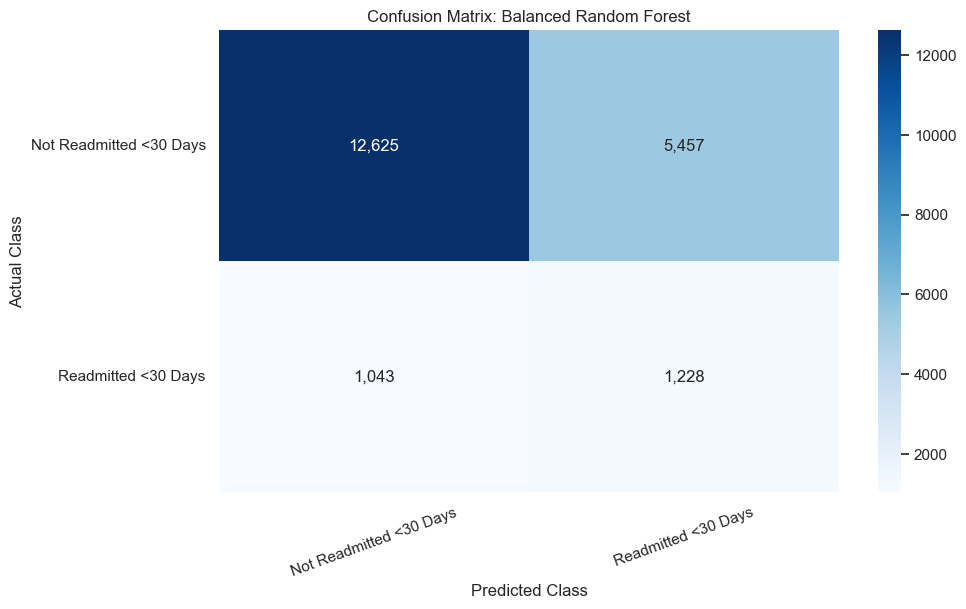

In [29]:
# Select the random forest predictions for the confusion matrix visualization.
preferred_predictions = y_pred_forest

# Calculate the confusion matrix using the testing target and preferred model predictions.
cm = confusion_matrix(y_test, preferred_predictions)

# Create readable labels for the confusion matrix rows and columns.
cm_labels = ["Not Readmitted <30 Days", "Readmitted <30 Days"]

# Create a heatmap from the confusion matrix so prediction errors are easier to interpret visually.
ax = sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=cm_labels, yticklabels=cm_labels)

# Add a title so the chart clearly identifies the model being evaluated.
ax.set_title("Confusion Matrix: Balanced Random Forest")

# Label the x-axis as predicted class.
ax.set_xlabel("Predicted Class")

# Label the y-axis as actual class.
ax.set_ylabel("Actual Class")

# Rotate x-axis labels slightly so they fit neatly in the exported PDF.
plt.xticks(rotation=20)

# Rotate y-axis labels to keep them readable.
plt.yticks(rotation=0)

# Show the completed confusion matrix chart.
plt.show()


The confusion matrix is important because it translates model performance into practical error types. False negatives represent patients who were actually readmitted within 30 days but were predicted as not readmitted. In a healthcare operations setting, those missed patients matter because they may represent missed opportunities for discharge planning, outreach, or follow-up care. False positives also matter because they could lead to extra outreach effort for patients who may not need it.


## ROC Curve and Precision-Recall Curve

ROC-AUC and PR-AUC evaluate model performance across different probability thresholds. The precision-recall curve is especially useful here because the readmission class is the minority class.


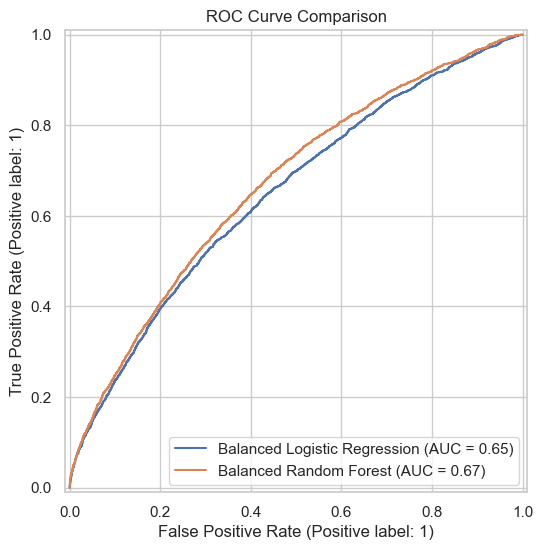

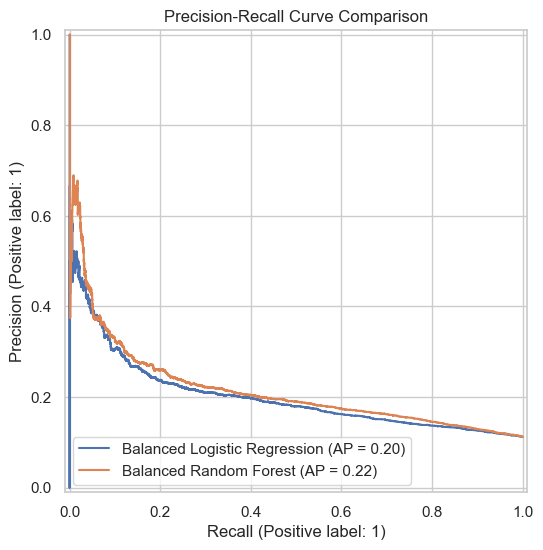

In [30]:
# Create an ROC curve display for the balanced logistic regression model.
RocCurveDisplay.from_predictions(y_test, y_prob_logistic, name="Balanced Logistic Regression")

# Add the random forest ROC curve to the same axes for comparison.
RocCurveDisplay.from_predictions(y_test, y_prob_forest, name="Balanced Random Forest", ax=plt.gca())

# Add a chart title that explains the comparison.
plt.title("ROC Curve Comparison")

# Show the ROC curve chart.
plt.show()

# Create a precision-recall curve display for the balanced logistic regression model.
PrecisionRecallDisplay.from_predictions(y_test, y_prob_logistic, name="Balanced Logistic Regression")

# Add the random forest precision-recall curve to the same axes for comparison.
PrecisionRecallDisplay.from_predictions(y_test, y_prob_forest, name="Balanced Random Forest", ax=plt.gca())

# Add a chart title that explains the comparison.
plt.title("Precision-Recall Curve Comparison")

# Show the precision-recall curve chart.
plt.show()


The ROC curve shows how well the model separates the two classes across thresholds. The precision-recall curve is even more relevant for this project because the positive readmission class is much smaller than the negative class. In an imbalanced healthcare dataset, PR-AUC helps show whether the model is making useful positive predictions rather than simply benefiting from the large majority class.


## Feature Importance from the Random Forest Model

Feature importance helps explain which predictors contributed most to the random forest model. This is useful for interpretation, but it should not be treated as proof of causation.


,feature,importance
9,number_inpatient,0.1494
37,prior_utilization_total,0.1092
38,prior_inpatient_flag,0.1011
1,discharge_disposition_id,0.0989
40,medications_per_day,0.0534
4,num_lab_procedures,0.0506
6,num_medications,0.0487
3,time_in_hospital,0.0433
12,age_midpoint,0.0334
10,number_diagnoses,0.0308


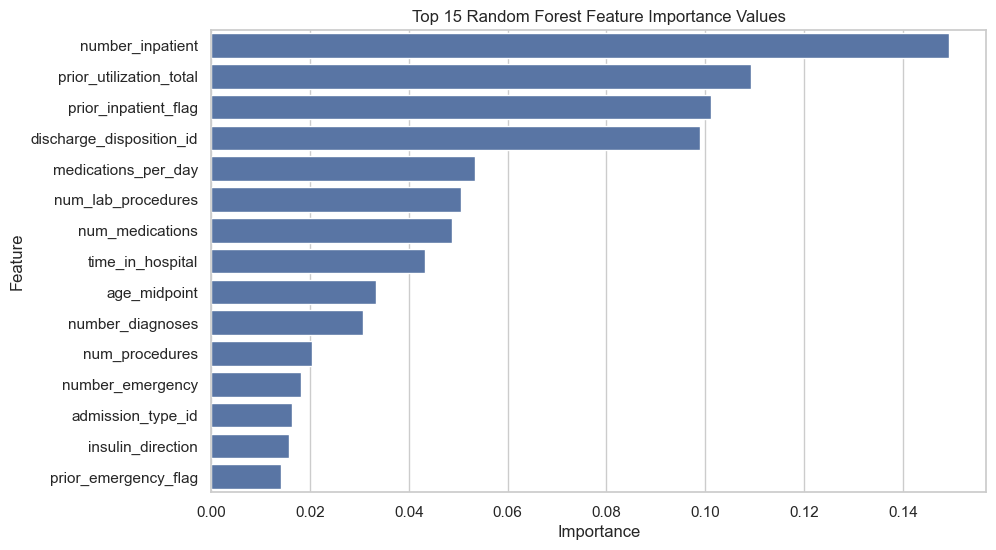

In [31]:
# Extract feature importance values from the trained random forest model.
feature_importance_values = random_forest_model.feature_importances_

# Create a DataFrame pairing each feature name with its importance value.
feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": feature_importance_values
})

# Sort the feature importance table from highest to lowest importance.
feature_importance = feature_importance.sort_values(by="importance", ascending=False)

# Select the top 15 features so the chart remains readable.
top_features = feature_importance.head(15)

# Display the top feature table so exact values are available for interpretation.
display(top_features.round(4))

# Create a horizontal bar chart for the top feature importance values.
ax = sns.barplot(data=top_features, x="importance", y="feature")

# Add a title so the chart clearly explains what is being ranked.
ax.set_title("Top 15 Random Forest Feature Importance Values")

# Label the x-axis as importance.
ax.set_xlabel("Importance")

# Label the y-axis as feature names.
ax.set_ylabel("Feature")

# Show the feature importance chart.
plt.show()


The feature importance table helps identify which variables the random forest used most often when separating readmission and non-readmission encounters. After removing target-related fields, the most important predictors should reflect actual patient, utilization, diagnosis, medication, or demographic information rather than a direct label of the outcome. These importance values should be interpreted as model-based associations rather than proof that a feature causes readmission.


## Fairness-Aware Subgroup Review

Because this project has a healthcare bias focus, the final evaluation includes a subgroup review by race and gender where enough observations are available. This does not prove bias, but it helps identify whether model predictions or errors appear uneven across demographic groups.


In [32]:
# Create an evaluation DataFrame using the testing target index.
evaluation_df = pd.DataFrame(index=y_test.index)

# Store the actual testing target values in the evaluation DataFrame.
evaluation_df["actual_readmit_30"] = y_test

# Store the random forest predicted class values in the evaluation DataFrame.
evaluation_df["predicted_readmit_30"] = y_pred_forest

# Store the random forest predicted probabilities in the evaluation DataFrame.
evaluation_df["predicted_probability"] = y_prob_forest

# Add race values from the prepared modeling DataFrame when the column is available.
if "race" in model_df.columns:
    evaluation_df["race"] = model_df.loc[y_test.index, "race"]

# Add gender values from the prepared modeling DataFrame when the column is available.
if "gender" in model_df.columns:
    evaluation_df["gender"] = model_df.loc[y_test.index, "gender"]

# Define a helper function to summarize model performance for demographic subgroups.
def subgroup_metrics(data, group_column):
    # Create an empty list that will hold one summary dictionary for each subgroup.
    rows = []
    
    # Loop through each subgroup and its matching records.
    for group_value, group_data in data.dropna(subset=[group_column]).groupby(group_column):
        # Skip very small subgroups because unstable rates may be misleading.
        if len(group_data) < 100:
            continue
        
        # Store the actual class values for the current subgroup.
        actual = group_data["actual_readmit_30"]
        
        # Store the predicted class values for the current subgroup.
        predicted = group_data["predicted_readmit_30"]
        
        # Calculate the subgroup confusion matrix using a fixed label order.
        tn, fp, fn, tp = confusion_matrix(actual, predicted, labels=[0, 1]).ravel()
        
        # Calculate subgroup recall while preventing divide-by-zero problems.
        subgroup_recall = tp / (tp + fn) if (tp + fn) > 0 else np.nan
        
        # Calculate subgroup false positive rate while preventing divide-by-zero problems.
        subgroup_fpr = fp / (fp + tn) if (fp + tn) > 0 else np.nan
        
        # Add the subgroup summary to the list of rows.
        rows.append({
            "group_variable": group_column,
            "group": group_value,
            "count": len(group_data),
            "actual_readmission_rate": actual.mean(),
            "predicted_readmission_rate": predicted.mean(),
            "recall_for_readmitted_class": subgroup_recall,
            "false_positive_rate": subgroup_fpr
        })
    
    # Convert the subgroup summary rows into a DataFrame.
    return pd.DataFrame(rows)

# Calculate subgroup performance by race when race is available.
race_subgroup_results = subgroup_metrics(evaluation_df, "race") if "race" in evaluation_df.columns else pd.DataFrame()

# Calculate subgroup performance by gender when gender is available.
gender_subgroup_results = subgroup_metrics(evaluation_df, "gender") if "gender" in evaluation_df.columns else pd.DataFrame()

# Combine race and gender subgroup results into one table.
subgroup_results = pd.concat([race_subgroup_results, gender_subgroup_results], ignore_index=True)

# Display subgroup results rounded to four decimal places for readability.
display(subgroup_results.round(4))


,group_variable,group,count,actual_readmission_rate,predicted_readmission_rate,recall_for_readmitted_class,false_positive_rate
0,race,AfricanAmerican,3882,0.1113,0.3405,0.5231,0.3177
1,race,Asian,113,0.0885,0.2389,0.2000,0.2427
2,race,Caucasian,15203,0.1129,0.3347,0.5527,0.3070
3,race,Hispanic,403,0.1241,0.2605,0.5600,0.2181
4,race,Missing,469,0.0896,0.1557,0.3095,0.1405
5,race,Other,283,0.0707,0.2438,0.5000,0.2243
6,gender,Female,11055,0.1135,0.3414,0.5530,0.3143
7,gender,Male,9298,0.1093,0.3131,0.5256,0.2870


The Asian subgroup has a much smaller test-set count than the largest groups, so its recall estimate should be interpreted cautiously. The variation across groups does not prove bias, but it does suggest that the final project should continue monitoring subgroup performance and avoid relying only on overall model metrics.

This subgroup review is an early fairness-aware diagnostic rather than a final fairness conclusion. The table compares readmission recall and false positive rates across race and gender groups with sufficient sample size. Large differences across groups would suggest that the final project should include deeper subgroup evaluation, threshold review, and discussion of whether the model performs consistently across patient populations.

Because race and gender are sensitive demographic fields, a production version of this project should compare model performance with and without those fields. In this academic notebook, they are retained to support subgroup review and bias-aware interpretation, not to recommend automated clinical decisions based on protected attributes.

After checking the predictor set for target leakage, the model results should be interpreted as estimates of performance using available patient, utilization, medication, diagnosis, and demographic features. Any target-derived fields were removed before training. This makes the evaluation more realistic because the models no longer have direct access to the answer they are trying to predict.

## Milestone 3 Model Selection Summary

The selected modeling approach is classification because the target is binary: whether the encounter resulted in readmission within 30 days. Logistic regression was selected because it provides an interpretable baseline that is appropriate for binary outcomes. Random forest was selected because hospital readmission risk may involve nonlinear patterns across utilization, medication, diagnosis, and demographic variables.

The selected evaluation metrics are accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC. Accuracy is included only as a general reference because it can be misleading with an imbalanced target. Recall is especially important because it measures how many true readmissions the model identifies. Precision is also important because it shows how many predicted readmissions are correct. F1-score balances precision and recall, while ROC-AUC and PR-AUC summarize performance across probability thresholds.

For this milestone, the balanced random forest is the preferred model because it provides the strongest balance of F1-score and PR-AUC while maintaining useful recall for the readmission class.


# Overall Conclusion for Milestones 1-3

This notebook builds a clear path from healthcare business problem to data preparation and early model evaluation. Milestone 1 established the project focus: predicting 30 day diabetic hospital readmission risk while staying alert to possible bias across demographic groups. The exploratory analysis showed that the target is imbalanced, with far fewer encounters readmitted within 30 days than not readmitted within 30 days. That finding shaped the rest of the project because it made accuracy alone an inappropriate evaluation strategy.

Milestone 2 prepared the data for modeling by selecting relevant variables, addressing missing values, transforming categorical and ordered fields, engineering features, creating diagnosis groupings, dummy encoding categorical variables, and creating a stratified train-test split. This preparation step matters because machine learning models are only as reliable as the data structure provided to them.

Milestone 3 trained and evaluated classification models using methods that fit the problem. The baseline model showed why a simple majority-class approach is not useful for identifying readmission risk. After removing target-related fields from the predictor set, the balanced logistic regression and balanced random forest models can be evaluated more realistically using recall, precision, F1-score, ROC-AUC, and PR-AUC. These metrics are better suited than accuracy alone because the readmission class is much smaller than the non-readmission class.

A key limitation is that the model shows modest predictive strength rather than high precision. This is common in imbalanced healthcare prediction tasks, but it means the model should be viewed as an early screening tool for follow-up review rather than a standalone decision-making system.

The main insight from this milestone is that predictive modeling in healthcare should not stop at overall accuracy. A useful readmission model must be evaluated based on how well it identifies the smaller high-risk group, how many false alarms it creates, and whether performance appears uneven across demographic groups. This connects to the course readings and videos because model building is not only about fitting an algorithm. It also requires thoughtful feature preparation, metric selection, validation, interpretation, and awareness of the limitations of the data.

For the final project, the next steps should include refining the preferred model, considering threshold tuning on a validation set, comparing additional algorithms if needed, documenting limitations, and expanding the fairness-aware evaluation. The model should be presented as a decision-support tool for identifying patients who may benefit from additional follow-up, not as a replacement for clinical judgment.


# Final Project Additions Since Milestone 3

The following section has been added after Milestone 3 for the final project submission. Milestone 3 trained and evaluated the baseline model, balanced logistic regression model, and balanced random forest model. The final project adds an additional threshold review, an operational interpretation table, and a complete project writeup that addresses the professor's final submission requirements.

The new analysis is intentionally limited and practical. Instead of replacing the Milestone 3 model, it adds a final review of how the preferred model could be interpreted before any real-world use. This matters because the project outcome is imbalanced, and changing a probability threshold can affect how many true readmissions are found and how many false positive outreach cases are created.


## Final Threshold Sensitivity Review

The next code block reviews several probability thresholds for the preferred balanced random forest model. The default model threshold is usually 0.50, but healthcare screening problems sometimes require a different threshold because missing a high-risk patient and creating an extra outreach case do not have the same operational meaning.

This analysis does not automatically choose a production threshold. It shows the tradeoff between recall, precision, false positives, and false negatives so stakeholders can understand what changes when the model is made more or less sensitive.

For a limited pilot, the 0.50 threshold appears more operationally realistic because it reduces false positives compared with lower thresholds, but the final threshold should be selected with stakeholder input based on outreach capacity and the acceptable risk of missed readmissions.

In [33]:
# Create a list of probability thresholds to compare for the preferred model.
threshold_values = [0.30, 0.35, 0.40, 0.45, 0.50]

# Create an empty list that will store one dictionary of metrics for each threshold.
threshold_rows = []

# Loop through each probability threshold so the model can be evaluated at several decision points.
for threshold in threshold_values:
    # Convert predicted probabilities into class predictions using the current threshold.
    threshold_predictions = (y_prob_forest >= threshold).astype(int)
    
    # Calculate the confusion matrix values using a fixed class order of 0 and 1.
    tn, fp, fn, tp = confusion_matrix(y_test, threshold_predictions, labels=[0, 1]).ravel()
    
    # Calculate accuracy so the table still includes the familiar overall metric.
    threshold_accuracy = accuracy_score(y_test, threshold_predictions)
    
    # Calculate precision to show how many predicted readmissions were truly readmitted.
    threshold_precision = precision_score(y_test, threshold_predictions, zero_division=0)
    
    # Calculate recall to show how many true readmissions were identified by the model.
    threshold_recall = recall_score(y_test, threshold_predictions, zero_division=0)
    
    # Calculate F1-score to summarize the balance between precision and recall.
    threshold_f1 = f1_score(y_test, threshold_predictions, zero_division=0)
    
    # Calculate the false positive rate so the outreach burden can be considered.
    false_positive_rate = fp / (fp + tn) if (fp + tn) > 0 else np.nan
    
    # Add the current threshold results to the summary list.
    threshold_rows.append({
        "threshold": threshold,
        "accuracy": threshold_accuracy,
        "precision": threshold_precision,
        "recall": threshold_recall,
        "f1_score": threshold_f1,
        "false_positive_rate": false_positive_rate,
        "true_positives": tp,
        "false_positives": fp,
        "false_negatives": fn,
        "true_negatives": tn
    })

# Convert the threshold results list into a DataFrame for easier display.
threshold_review = pd.DataFrame(threshold_rows)

# Display the threshold review rounded to four decimal places for readability.
display(threshold_review.round(4))

,threshold,accuracy,precision,recall,f1_score,false_positive_rate,true_positives,false_positives,false_negatives,true_negatives
0,0.30,0.1706,0.1167,0.9793,0.2085,0.9310,2224,16834,47,1248
1,0.35,0.2640,0.1248,0.9309,0.2201,0.8197,2114,14822,157,3260
2,0.40,0.3943,0.1383,0.8463,0.2377,0.6624,1922,11978,349,6104
3,0.45,0.5380,0.1580,0.7252,0.2594,0.4855,1647,8779,624,9303
4,0.50,0.6806,0.1837,0.5407,0.2742,0.3018,1228,5457,1043,12625


The threshold review is important because a healthcare readmission model is not just a technical exercise. A lower threshold may identify more true readmissions, but it can also create more false positives and increase the amount of follow-up work for care teams. A higher threshold may reduce unnecessary outreach, but it may miss more patients who are actually readmitted. For this reason, the final project treats threshold selection as a stakeholder and workflow decision rather than a purely mathematical decision.

## Final Operational Interpretation Table

The next code block creates a concise final interpretation table for the preferred model. This table is designed for a stakeholder audience because it connects model performance to practical use. The goal is to show whether the model is ready for deployment, what role it could play, and what safeguards would be needed before operational use.

In [34]:
# Select the balanced random forest row from the model comparison table.
preferred_model_row = model_comparison[model_comparison["model"] == "Balanced Random Forest"].iloc[0]

# Create a final interpretation table that summarizes the preferred model in plain business terms.
final_operational_summary = pd.DataFrame({
    # Store the name of the preferred model from the Milestone 3 evaluation.
    "Final Review Item": [
        "Preferred model",
        "Primary use case",
        "Important strength",
        "Important limitation",
        "Deployment readiness",
        "Recommended next step"
    ],
    # Store the final interpretation connected to the project findings.
    "Interpretation": [
        "Balanced Random Forest",
        "Early screening support for patients who may benefit from follow-up after discharge",
        f"Improved recall compared with a majority-class baseline; test recall was {preferred_model_row['recall']:.4f}",
        f"Precision remained modest at {preferred_model_row['precision']:.4f}, so many positive predictions would require review",
        "Not ready for full deployment without validation, threshold review, subgroup monitoring, and clinical workflow testing",
        "Pilot the model as a decision-support flag and evaluate outcomes, workload, and subgroup performance before broader use"
    ]
})

# Display the final interpretation table for the notebook reader.
display(final_operational_summary)

,Final Review Item,Interpretation
0,Preferred model,Balanced Random Forest
1,Primary use case,Early screening support for patients who may b...
2,Important strength,Improved recall compared with a majority-class...
3,Important limitation,"Precision remained modest at 0.1837, so many p..."
4,Deployment readiness,Not ready for full deployment without validati...
5,Recommended next step,Pilot the model as a decision-support flag and...


This final interpretation table supports the conclusion that the model is better suited as an early decision-support tool than as a deployed automated decision system. The model can help identify patients for review, but its modest precision means that clinical teams would still need human judgment, workflow limits, and additional validation before use.

# Final Project Writeup

## Introduction and Problem Statement

This project examines whether data mining techniques can be used to predict 30 day hospital readmission risk for diabetic patients while also remaining aware of potential bias across demographic groups. The project uses the Diabetes 130-US Hospitals for Years 1999 to 2008 dataset from the UCI Machine Learning Repository. The target outcome is whether an encounter resulted in readmission within 30 days, derived from the original `readmitted` field.

The problem is important because hospital readmissions are costly, operationally disruptive, and often connected to gaps in discharge planning, medication management, follow-up care, patient education, or broader access barriers. For patients with diabetes, the risk can be especially important because diabetes management often requires coordination across medication, labs, outpatient follow-up, and patient self-management. A model that can identify patients who may be at higher risk could help a healthcare organization prioritize outreach and care coordination.

This problem also has a fairness and ethics component. A model may look acceptable overall while performing differently across patient groups. Because race, gender, and age are included in the dataset, this project does not treat fairness as an afterthought. Instead, it includes subgroup review as part of responsible model evaluation. The goal is not to prove discrimination from this dataset alone, but to identify whether model performance should be monitored before any operational use.

## Stakeholder Pitch

The stakeholder pitch for this project is that a hospital system could use predictive modeling as an early warning tool to help care teams identify diabetic patients who may need additional support after discharge. The model would not replace clinical judgment. Instead, it could help prioritize limited care coordination resources by flagging patients who may benefit from medication review, discharge education, follow-up scheduling, or outreach.

The business value is practical. If a hospital can identify some higher-risk patients earlier, it may reduce avoidable readmissions, improve care transitions, and focus staff effort more effectively. The fairness value is also important. Before using a model in healthcare operations, stakeholders should understand whether the model performs consistently across demographic groups and whether it creates uneven error patterns.

## Data Source

The data comes from the UCI Machine Learning Repository's Diabetes 130-US Hospitals for Years 1999 to 2008 dataset. The dataset contains more than 100,000 diabetic hospital encounters from 130 United States hospitals. It includes demographic fields, utilization fields, diagnosis fields, medication fields, lab result indicators, hospital stay information, and readmission status.

The notebook uses the `ucimlrepo` package to load the dataset directly when possible. A local CSV fallback is also included so the notebook can still run if the UCI connection is unavailable because of an internet, server, or SSL certificate issue. This improves reproducibility and protects the project from depending entirely on a live web connection.

## Organized Summary of Milestone 1

Milestone 1 introduced the healthcare business problem and framed the project as a binary classification problem. The target was created from the original `readmitted` field by identifying whether a patient was readmitted within 30 days. The exploratory data analysis showed that the target was highly imbalanced, with a much smaller percentage of encounters readmitted within 30 days than not readmitted within 30 days.

Milestone 1 also included several visual reviews. The target distribution chart showed the class imbalance problem. The race and gender charts supported the bias-aware focus by comparing estimated readmission rates across demographic groups. The time-in-hospital chart reviewed whether length of stay appeared different across readmission groups. The age-group chart added another demographic view and helped show that age may be relevant to both patient complexity and later fairness review.

The main learning from Milestone 1 was that accuracy alone would not be enough for this project. A model could predict the majority class most of the time and still look accurate while failing to identify patients who were actually readmitted within 30 days.

## Organized Summary of Milestone 2

Milestone 2 moved the project from exploration into data preparation. The notebook selected a working modeling dataset, removed fields that were not appropriate for first-pass modeling, handled missing values, transformed ordered and clinical variables, engineered new features, extracted diagnosis categories, created dummy variables, and built a stratified train-test split.

Missing data was handled based on the meaning of the field rather than through blind row deletion. For example, missing race values were preserved as a category so the record could remain available while still documenting that the value was not recorded. Lab result fields were treated as meaningful categories because a missing lab result may reflect that the test was not measured. Very sparse or high-risk fields were removed when they were not appropriate for the first modeling dataset.

Feature engineering created additional variables connected to patient complexity and utilization, such as prior utilization totals, inpatient flags, medication burden, and diagnosis groupings. These features were created without using the target outcome to avoid data snooping.

The main learning from Milestone 2 was that model quality depends heavily on data preparation. The project needed careful handling of missing values, categorical fields, class imbalance, and potential leakage before model training could be meaningful.

## Organized Summary of Milestone 3

Milestone 3 trained and evaluated classification models. The notebook included a majority-class baseline, a balanced logistic regression model, and a balanced random forest model. The baseline model was important because it showed why the project could not rely on accuracy. Since most encounters were not readmitted within 30 days, a majority-class model could appear accurate while identifying no true readmissions.

The balanced logistic regression model provided an interpretable model for comparison. The balanced random forest model provided a nonlinear model that could capture more complex relationships across utilization, diagnosis, medication, hospital stay, and demographic variables. Both models used class weighting because the readmission class was much smaller than the non-readmission class.

The model evaluation included accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, classification reports, confusion matrix review, ROC and precision-recall curves, feature importance, and subgroup review. The balanced random forest was selected as the preferred model because it provided the strongest balance of F1-score and PR-AUC while maintaining useful recall for the readmission class.

## Final Additions Since Milestone 3

The final project adds a threshold sensitivity review and an operational interpretation table. The threshold review is included because the default 0.50 probability threshold may not be the best choice for a healthcare screening problem. Lowering the threshold may identify more true readmissions, but it can also increase false positives and create more follow-up work. Raising the threshold may reduce false positives, but it may miss patients who need support.

The operational interpretation table summarizes the preferred model in stakeholder terms. It explains that the model may be useful as an early screening tool, but it is not ready for full deployment. The model needs further validation, threshold selection, subgroup monitoring, and workflow testing before it could be responsibly used.

## EDA and Important Visuals

The most important EDA visual is the target distribution chart because it explains the rest of the modeling strategy. The outcome is imbalanced, so the project must evaluate models with recall, precision, F1-score, ROC-AUC, and PR-AUC rather than accuracy alone.

The race, gender, and age charts are also important because the project includes a healthcare bias lens. These charts do not prove bias or causation, but they help identify whether demographic patterns should be monitored during model evaluation. The time-in-hospital comparison is useful because it examines whether one operational hospital stay measure appears different across readmission outcomes.

## Data Preparation Summary

The data preparation process included several important steps. First, the original readmission field was converted into a binary target. Second, missing values were replaced with meaningful categories or flags where appropriate. Third, fields that were too sparse, risky, or not useful for modeling were removed. Fourth, ordered and clinical fields were transformed into numeric indicators. Fifth, diagnosis fields were grouped to reduce sparsity. Sixth, categorical variables were converted into dummy variables. Seventh, the dataset was split into training and testing sets using stratification so the target distribution was preserved.

This preparation supports responsible modeling because it reduces leakage risk, documents missingness, preserves useful records, and creates a model-ready feature matrix.

## Model Building and Evaluation Summary

The project trained three model types: a majority-class baseline, balanced logistic regression, and balanced random forest. The baseline provided a reference point and showed that accuracy can be misleading. The logistic regression model supported interpretability. The random forest model allowed nonlinear patterns and feature interactions.

The preferred model was the balanced random forest. It improved substantially over the baseline in identifying the positive readmission class. However, the model also had modest precision, meaning that many positive predictions would need review. In operational terms, this model would be more appropriate as a screening aid than as an automated decision tool.

## Conclusion

The analysis shows that predicting 30 day diabetic hospital readmission is possible, but the model should be interpreted carefully. The project found a clear class imbalance issue, created a prepared modeling dataset, trained multiple models, and selected the balanced random forest as the preferred first-pass model. The model offers useful signal compared with the baseline, especially because the baseline does not identify any true readmissions. However, the model is not strong enough to be used as a standalone deployment decision.

The model is not ready for full production deployment. It may be ready for additional validation or a limited retrospective pilot. Before deployment, the organization should test the model on more recent data, confirm that the predictors are available before discharge decisions are made, review subgroup performance, select a threshold with stakeholder input, and evaluate whether the care team can handle the expected number of outreach cases.

My recommendation is to treat the model as a decision-support flag for care coordination review. The model should help identify patients who may need additional follow-up, but it should not deny care, replace clinical judgment, or make automated patient-level decisions. The model should be paired with monitoring for false negatives, false positives, subgroup performance, and operational workload.

Future opportunities include testing additional models, tuning thresholds on a validation set, comparing models with and without demographic variables, adding more recent data, using external social risk or follow-up care data if available, and evaluating whether model-guided outreach actually reduces readmissions. Potential challenges include data quality, missingness, historical bias, changing healthcare practices since the dataset period, class imbalance, stakeholder trust, and the risk of using a model beyond the limits of what the data can support.

This final project connects to the DSC550 course because it demonstrates the full data mining process: problem framing, data understanding, data preparation, modeling, evaluation, interpretation, and communication of limitations. The strongest lesson is that a model is not successful simply because it produces predictions. It must be evaluated in context, explained clearly, and reviewed for practical and ethical risks before being used in a real healthcare setting.

# Final Conclusion and Submission Note

This final notebook includes all code, content, and analysis from Milestones 1 through 3 along with the final project additions. It also includes a full project writeup inside the notebook so the PDF export will contain both the technical workflow and the final written summary required by the assignment. Because the dataset is loaded from an external UCI source rather than a Blackboard-provided file, the original `diabetic_data.csv` file will also be included with the Blackboard submission.

Before submitting, the notebook should be rerun from the top in the local DSC550 environment. If the live UCI connection fails, place `diabetic_data.csv` in the same folder as the notebook and rerun. After the notebook runs successfully, export the notebook to PDF and submit both the `.ipynb` file and the PDF file to Blackboard.

# Final References

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830. https://jmlr.csail.mit.edu/papers/v12/pedregosa11a.html

Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., & Clore, J. N. (2014). Impact of HbA1c measurement on hospital readmission rates: Analysis of 70,000 clinical database patient records. *BioMed Research International, 2014*, Article 781670. https://doi.org/10.1155/2014/781670

Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., & Clore, J. N. (2014). Diabetes 130-US hospitals for years 1999-2008 [Data set]. UCI Machine Learning Repository. https://doi.org/10.24432/C5230J
